# 🏈 Football for Data Scientists: a visual starter for the Big Data Bowl 2027

New to American football and the NFL Combine? No problem.

This notebook walks you through the basics of how the game works and what each Combine drill measures, so you're ready to dig into this year's Big Data Bowl.

Let's dive in!

In [1]:
import logging
from pathlib import Path
from urllib.request import urlretrieve

import matplotlib.patheffects as pe
import matplotlib.pyplot as plt
from matplotlib import font_manager
from matplotlib.patches import FancyBboxPatch, Rectangle
from matplotlib.path import Path as MplPath

# Fonts and the NFL logo live in the repo's assets/ folder; on Kaggle they're fetched from GitHub on first run
ASSETS = next((p for p in (Path("../assets"), Path("assets")) if p.exists()), Path("assets"))
ASSETS_URL = "https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets"


def asset(name):
    """Local path to a file in assets/, downloaded from the repo if missing (None when that fails)."""
    path = ASSETS / name
    if not path.exists():
        try:
            path.parent.mkdir(parents=True, exist_ok=True)
            urlretrieve(f"{ASSETS_URL}/{name}", path)
        except OSError:
            return None
    return path


# Broadcast typefaces (Barlow, SIL OFL): Barlow Condensed for titles and on-screen tags, Barlow for everything else.
# If they can't be loaded, the charts fall back to matplotlib's default font.
for name in ["BarlowCondensed-BoldItalic", "BarlowCondensed-ExtraBoldItalic",
             "Barlow-Regular", "Barlow-Medium", "Barlow-SemiBold", "Barlow-Bold"]:
    if font := asset(f"fonts/{name}.ttf"):
        font_manager.fontManager.addfont(font)
# DejaVu Sans only fills in glyphs Barlow lacks (▲ ■ ●); hide the warnings about weights it doesn't have
DISPLAY = ["Barlow Condensed", "DejaVu Sans"]
logging.getLogger("matplotlib.font_manager").setLevel(logging.ERROR)

# One colour per Combine position group, used in every chart: warm for offense, cool for defense
POS_COLORS = {"WR": "#e05fb4", "TE": "#ff9a3c", "OL": "#e5636b", "DL": "#8b7cf6", "DB": "#22c3d6"}
POS_NAMES = {"WR": "Wide receivers", "TE": "Tight ends", "OL": "Offensive line",
             "DL": "Defensive line", "DB": "Defensive backs"}

# Broadcast palette shared by every chart
NAVY, NAVY_2, ESPN_RED = "#0b1220", "#16213a", "#d50a0a"
TURF_A, TURF_B, ENDZONE = "#3f7d4e", "#468a56", "#2f6640"
LOS_BLUE, FIRST_DOWN_YELLOW = "#3b8cff", "#ffd23f"
SUBTLE, NOT_TRACKED = "#aab3c5", "#8a8f99"

# Render charts at 2x resolution so text stays sharp on high-DPI screens and when the notebook scales them down
%config InlineBackend.figure_format = "retina"
plt.rcParams.update({"figure.dpi": 150, "font.size": 11, "font.family": ["Barlow", "DejaVu Sans"]})


def broadcast_header(fig, title, subtitle, top=0.97, height=0.085):
    """Red accent bar + bold italic title + grey subtitle, top-left of the figure."""
    fig.add_artist(Rectangle((0.03, top - height), 0.007, height, transform=fig.transFigure, color=ESPN_RED))
    fig.text(0.045, top - 0.3 * height, title, color="white", fontsize=32, fontweight="heavy",
             fontstyle="italic", family=DISPLAY, va="center")
    fig.text(0.046, top - 0.85 * height, subtitle, color=SUBTLE, fontsize=13, fontweight="normal", va="center")


def chyron_box(point=False, pad=0.35, slant=0.4):
    """Box style for tag(): a parallelogram leaning with the italic text, optionally pointed on the right."""
    def path(x0, y0, width, height, mutation_size):
        p = pad * mutation_size
        x0, y0, x1, y1 = x0 - p, y0 - p, x0 + width + p, y0 + height + p
        s = (y1 - y0) * slant / 2                    # horizontal lean at the top and bottom edges
        tip = [(x1 + (y1 - y0) / 2, (y0 + y1) / 2)] if point else []
        verts = [(x0 - s, y0), (x1 - s, y0) if not point else (x1, y0), *tip,
                 (x1 + s, y1) if not point else (x1, y1), (x0 + s, y1)]
        return MplPath(verts + verts[:1], closed=True)
    return path


def tag(ax, x, y, text, fc, color="white", ha="left", point=False, **kw):
    """An on-screen label slanted like a TV caption bar; point=True makes it point right, at what it names."""
    ax.text(x, y, text, ha=ha, va="center", fontsize=11.5, fontweight="bold", fontstyle="italic", family=DISPLAY,
            color=color, zorder=7, bbox=dict(boxstyle=chyron_box(point), fc=fc, ec="none"), **kw)


def glow_line(ax, xs, ys, color):
    ax.plot(xs, ys, color=color, lw=4, zorder=2, solid_capstyle="butt",
            path_effects=[pe.Stroke(linewidth=10, foreground=color, alpha=0.25), pe.Normal()])


def draw_field(ax):
    """A to-scale NFL field: 120 x 53.3 yards, end zones from 0-10 and 110-120, mowed in 5-yard stripes."""
    for i, x in enumerate(range(10, 110, 5)):
        ax.add_patch(Rectangle((x, 0), 5, 53.3, color=TURF_A if i % 2 else TURF_B, zorder=0))
    for x0 in (0, 110):
        ax.add_patch(Rectangle((x0, 0), 10, 53.3, color=ENDZONE, zorder=0))
    ax.add_patch(Rectangle((0, 0), 120, 53.3, fill=False, ec="white", lw=3, zorder=1))
    for x in range(10, 111, 5):
        ax.plot([x, x], [0, 53.3], color="white", lw=2 if x in (10, 110) else 1.3, alpha=0.8, zorder=1)
    for x in range(11, 110):
        for y in (0.3, 23.58, 29.73, 53.0):
            ax.plot([x, x], [y - 0.35, y + 0.35], color="white", lw=0.8, alpha=0.6, zorder=1)
    for x in range(20, 101, 10):
        label = str(x - 10 if x <= 60 else 110 - x)
        for y, rot in ((9, 0), (44.3, 180)):
            ax.text(x, y, label, color="white", alpha=0.55, ha="center", va="center", fontsize=17,
                    fontweight="bold", rotation=rot, zorder=1)
    ax.set_facecolor(NAVY)
    ax.set_aspect("equal")
    ax.axis("off")

---
## 1 · How the NFL works
Two teams, **11 players each** on the field, over a **60-minute game** (four 15-minute quarters). Full rules: [2026 NFL Rulebook](https://operations.nfl.com/rules-officiating/2026-nfl-rulebook).

The offense gets **4 downs (attempts) to gain 10 yards**. Make it and the count resets to *1st & 10*; fail and the other team takes over at the spot of the ball.

| Score | Points | How |
| :--- | :---: | :--- |
| Touchdown | 6 | Carry or catch the ball into the opponent's end zone |
| Field goal | 3 | Kick it between the uprights |
| Safety | 2 | The defense tackles the ball carrier in his own end zone |
| Two-point try | 2 | After a touchdown: one play from the 2-yard line |
| Extra point | 1 | After a touchdown: a short kick |

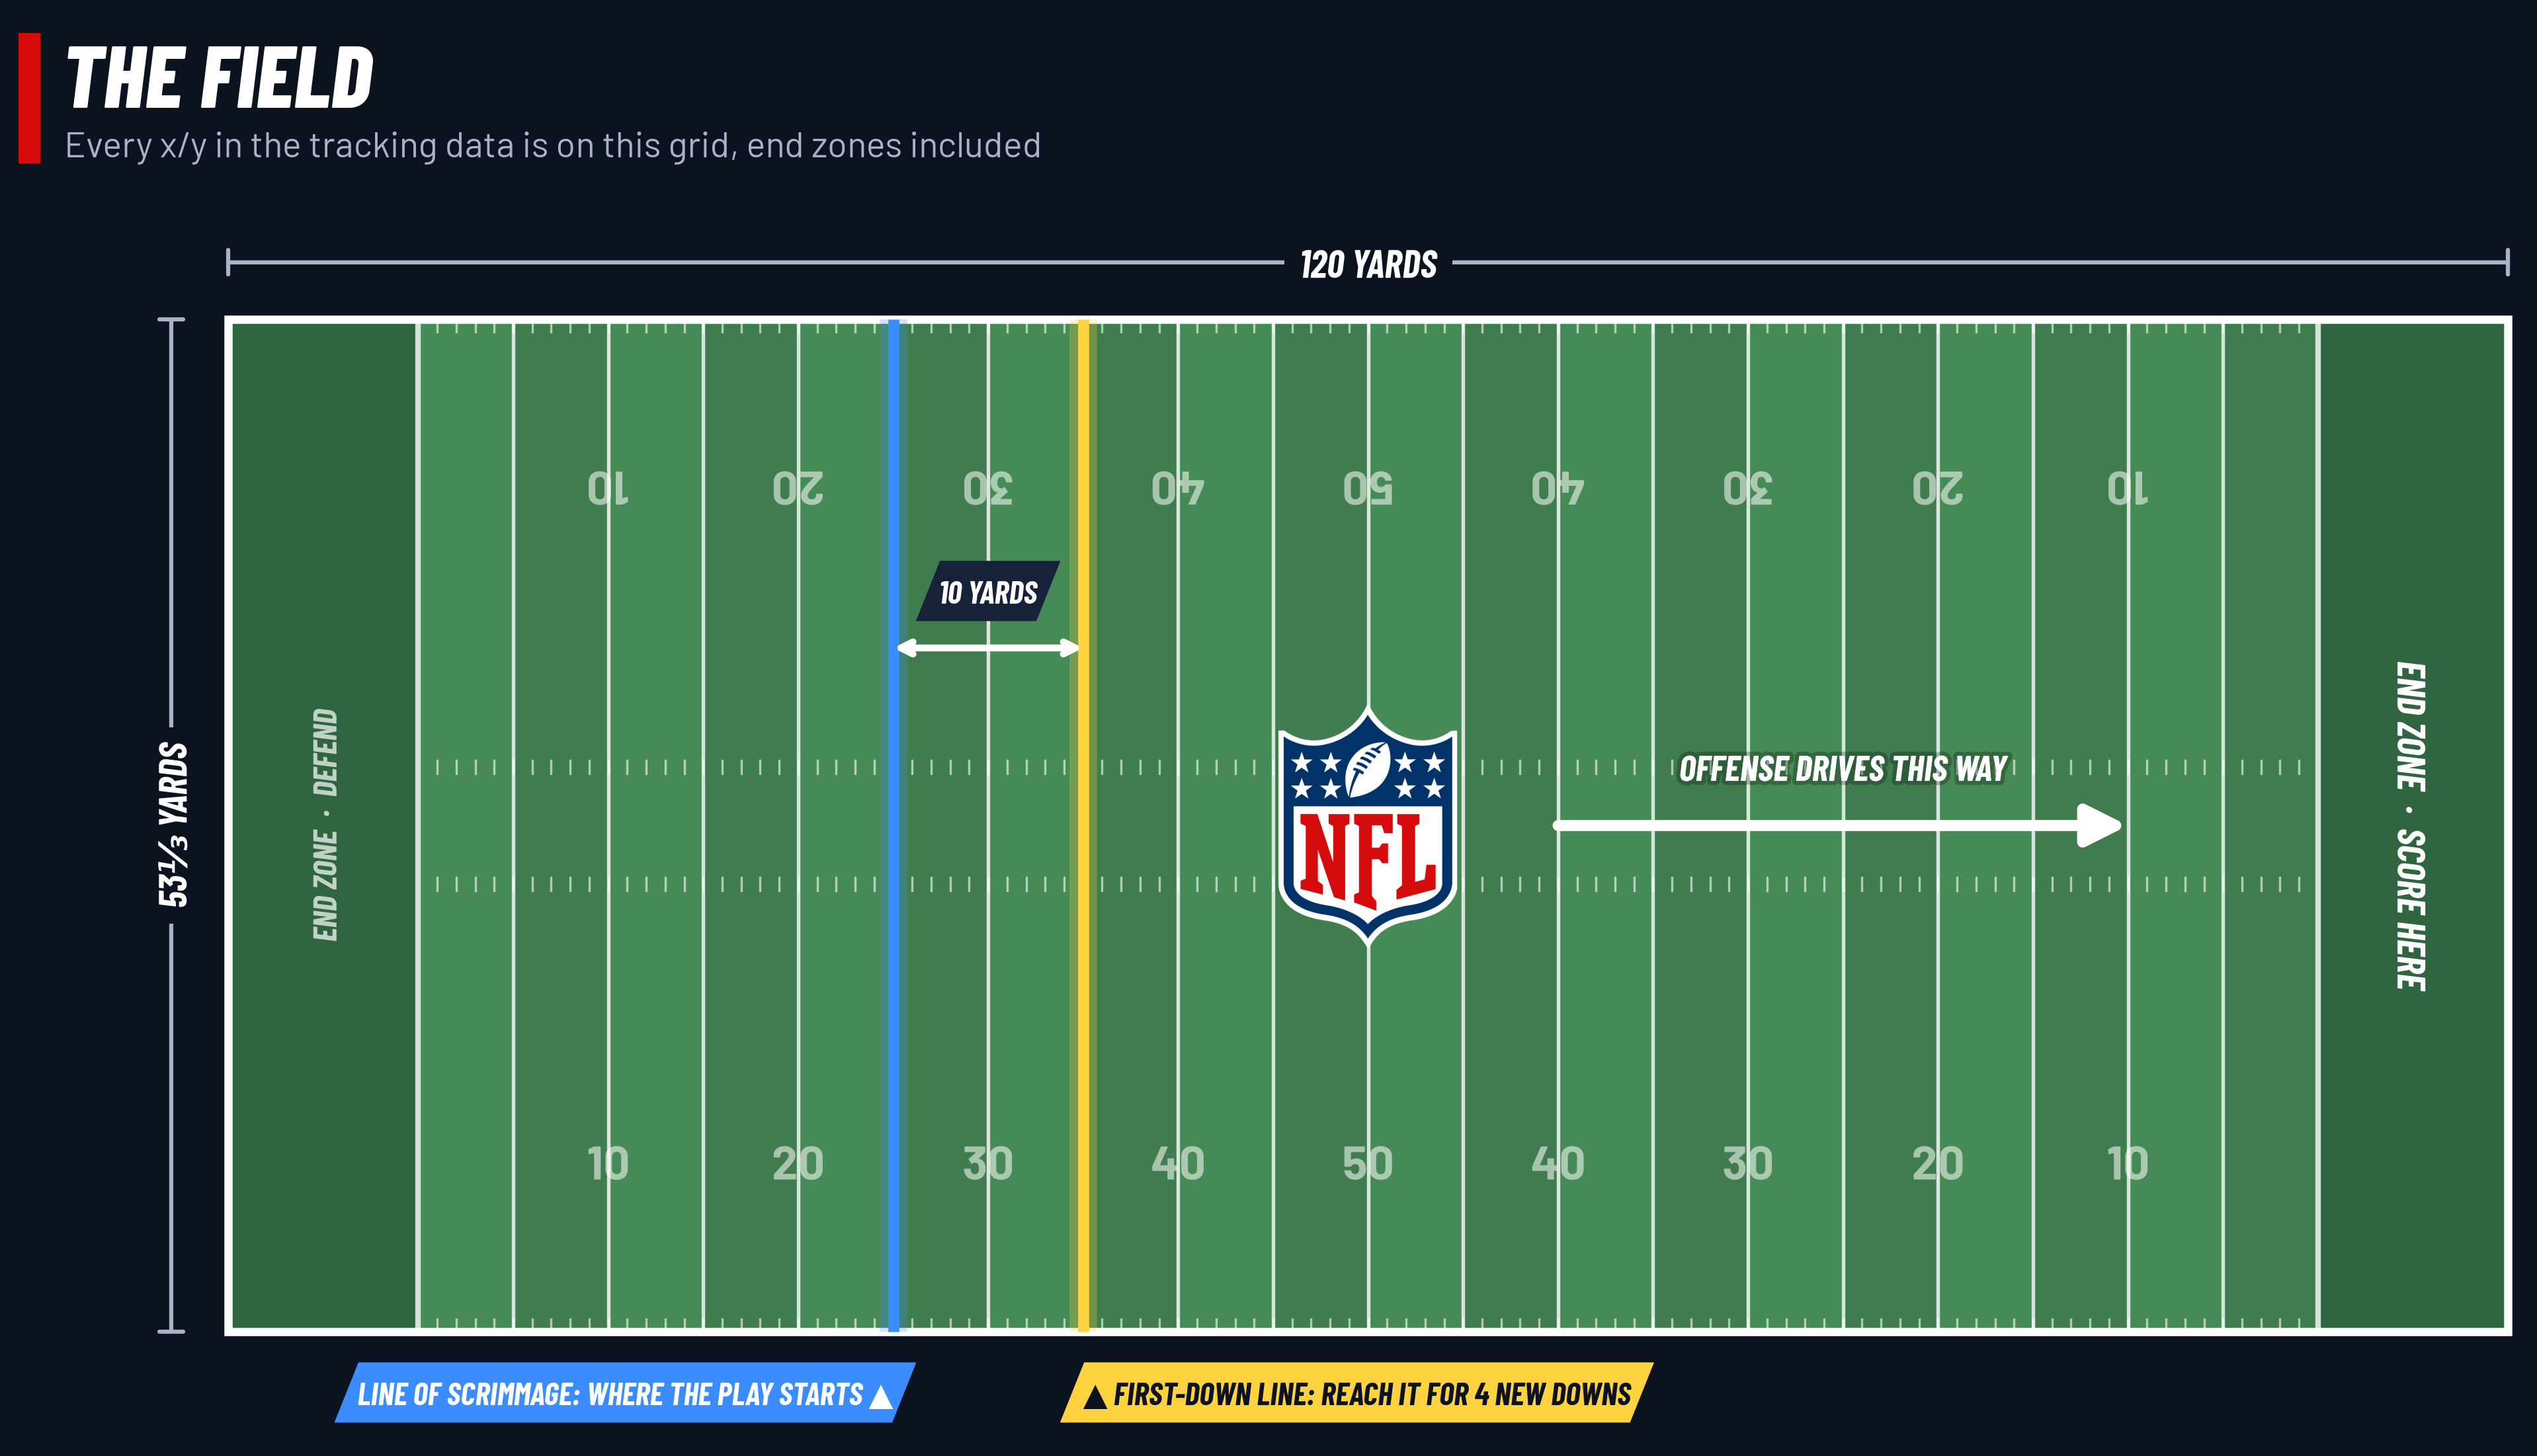

In [2]:
fig = plt.figure(figsize=(14, 7.6), facecolor=NAVY)
ax = fig.add_axes([0.03, 0.04, 0.94, 0.8])
draw_field(ax)
los, first_down = 35, 45
glow_line(ax, [los, los], [0, 53.3], LOS_BLUE)
glow_line(ax, [first_down, first_down], [0, 53.3], FIRST_DOWN_YELLOW)

# 10-yard bracket and drive direction
ax.annotate("", xy=(first_down, 36), xytext=(los, 36), zorder=4,
            arrowprops=dict(arrowstyle="<->", color="white", lw=2.5, shrinkA=0, shrinkB=0))
tag(ax, (los + first_down) / 2, 39, "10 YARDS", NAVY_2, ha="center")
ax.annotate("", xy=(100, 26.65), xytext=(70, 26.65), zorder=4,
            arrowprops=dict(arrowstyle="-|>", color="white", lw=4, mutation_scale=30, shrinkA=0, shrinkB=0),
            )
ax.text(85, 29, "OFFENSE DRIVES THIS WAY", color="white", ha="center", fontsize=13, fontweight="bold",
        fontstyle="italic", family=DISPLAY, zorder=4, path_effects=[pe.withStroke(linewidth=3, foreground="#00000040")])

# NFL shield at midfield (skipped if the image can't be loaded)
if LOGO := asset("nfl_logo.png"):
    logo = plt.imread(LOGO)
    h = 13                                           # shield height in yards
    w = h * logo.shape[1] / logo.shape[0]
    ax.imshow(logo, extent=(60 - w / 2, 60 + w / 2, 26.65 - h / 2, 26.65 + h / 2), zorder=2)

# Field dimensions along the sidelines
for xy, xytext, at, label, rot in (((0, 56.3), (120, 56.3), (60, 56.3), "120 YARDS", 0),
                                   ((-3, 0), (-3, 53.3), (-3, 26.65), "53⅓ YARDS", 90)):
    ax.annotate("", xy=xy, xytext=xytext, annotation_clip=False,
                arrowprops=dict(arrowstyle="|-|,widthA=0.4,widthB=0.4", color=SUBTLE, lw=1.5, shrinkA=0, shrinkB=0))
    ax.text(*at, label, color="white", ha="center", va="center", rotation=rot, fontsize=14, fontweight="bold",
            fontstyle="italic", family=DISPLAY, bbox=dict(boxstyle="square,pad=0.4", fc=NAVY, ec="none"))

# End zones
ax.text(115, 26.65, "END ZONE  ·  SCORE HERE", color="white", ha="center", va="center", rotation=270,
        fontsize=14, fontweight="bold", fontstyle="italic", family=DISPLAY, zorder=4)
ax.text(5, 26.65, "END ZONE  ·  DEFEND", color="white", alpha=0.7, ha="center", va="center", rotation=90,
        fontsize=12, fontweight="bold", fontstyle="italic", family=DISPLAY, zorder=4)

# Line tags hang below the field, pointing up at the line they name
tag(ax, los, -3.2, "LINE OF SCRIMMAGE: WHERE THE PLAY STARTS ▲", LOS_BLUE, ha="right", clip_on=False)
tag(ax, first_down, -3.2, "▲ FIRST-DOWN LINE: REACH IT FOR 4 NEW DOWNS", FIRST_DOWN_YELLOW, NAVY, clip_on=False)
ax.set_xlim(-5, 120.5)
ax.set_ylim(-5.5, 58)
broadcast_header(fig, "THE FIELD", "Every x/y in the tracking data is on this grid, end zones included")
plt.show()

---
## 2 · Who's on the field?
Every play is 11 vs 11, and each player has a specialised job that shapes the **body type** and **skills** scouts look for at the Combine.
The Combine data groups prospects into **five position groups** (`combine_position`), coloured below. Everyone in grey has no Combine drills in this dataset, and the white arrows show where each receiver runs on the play.

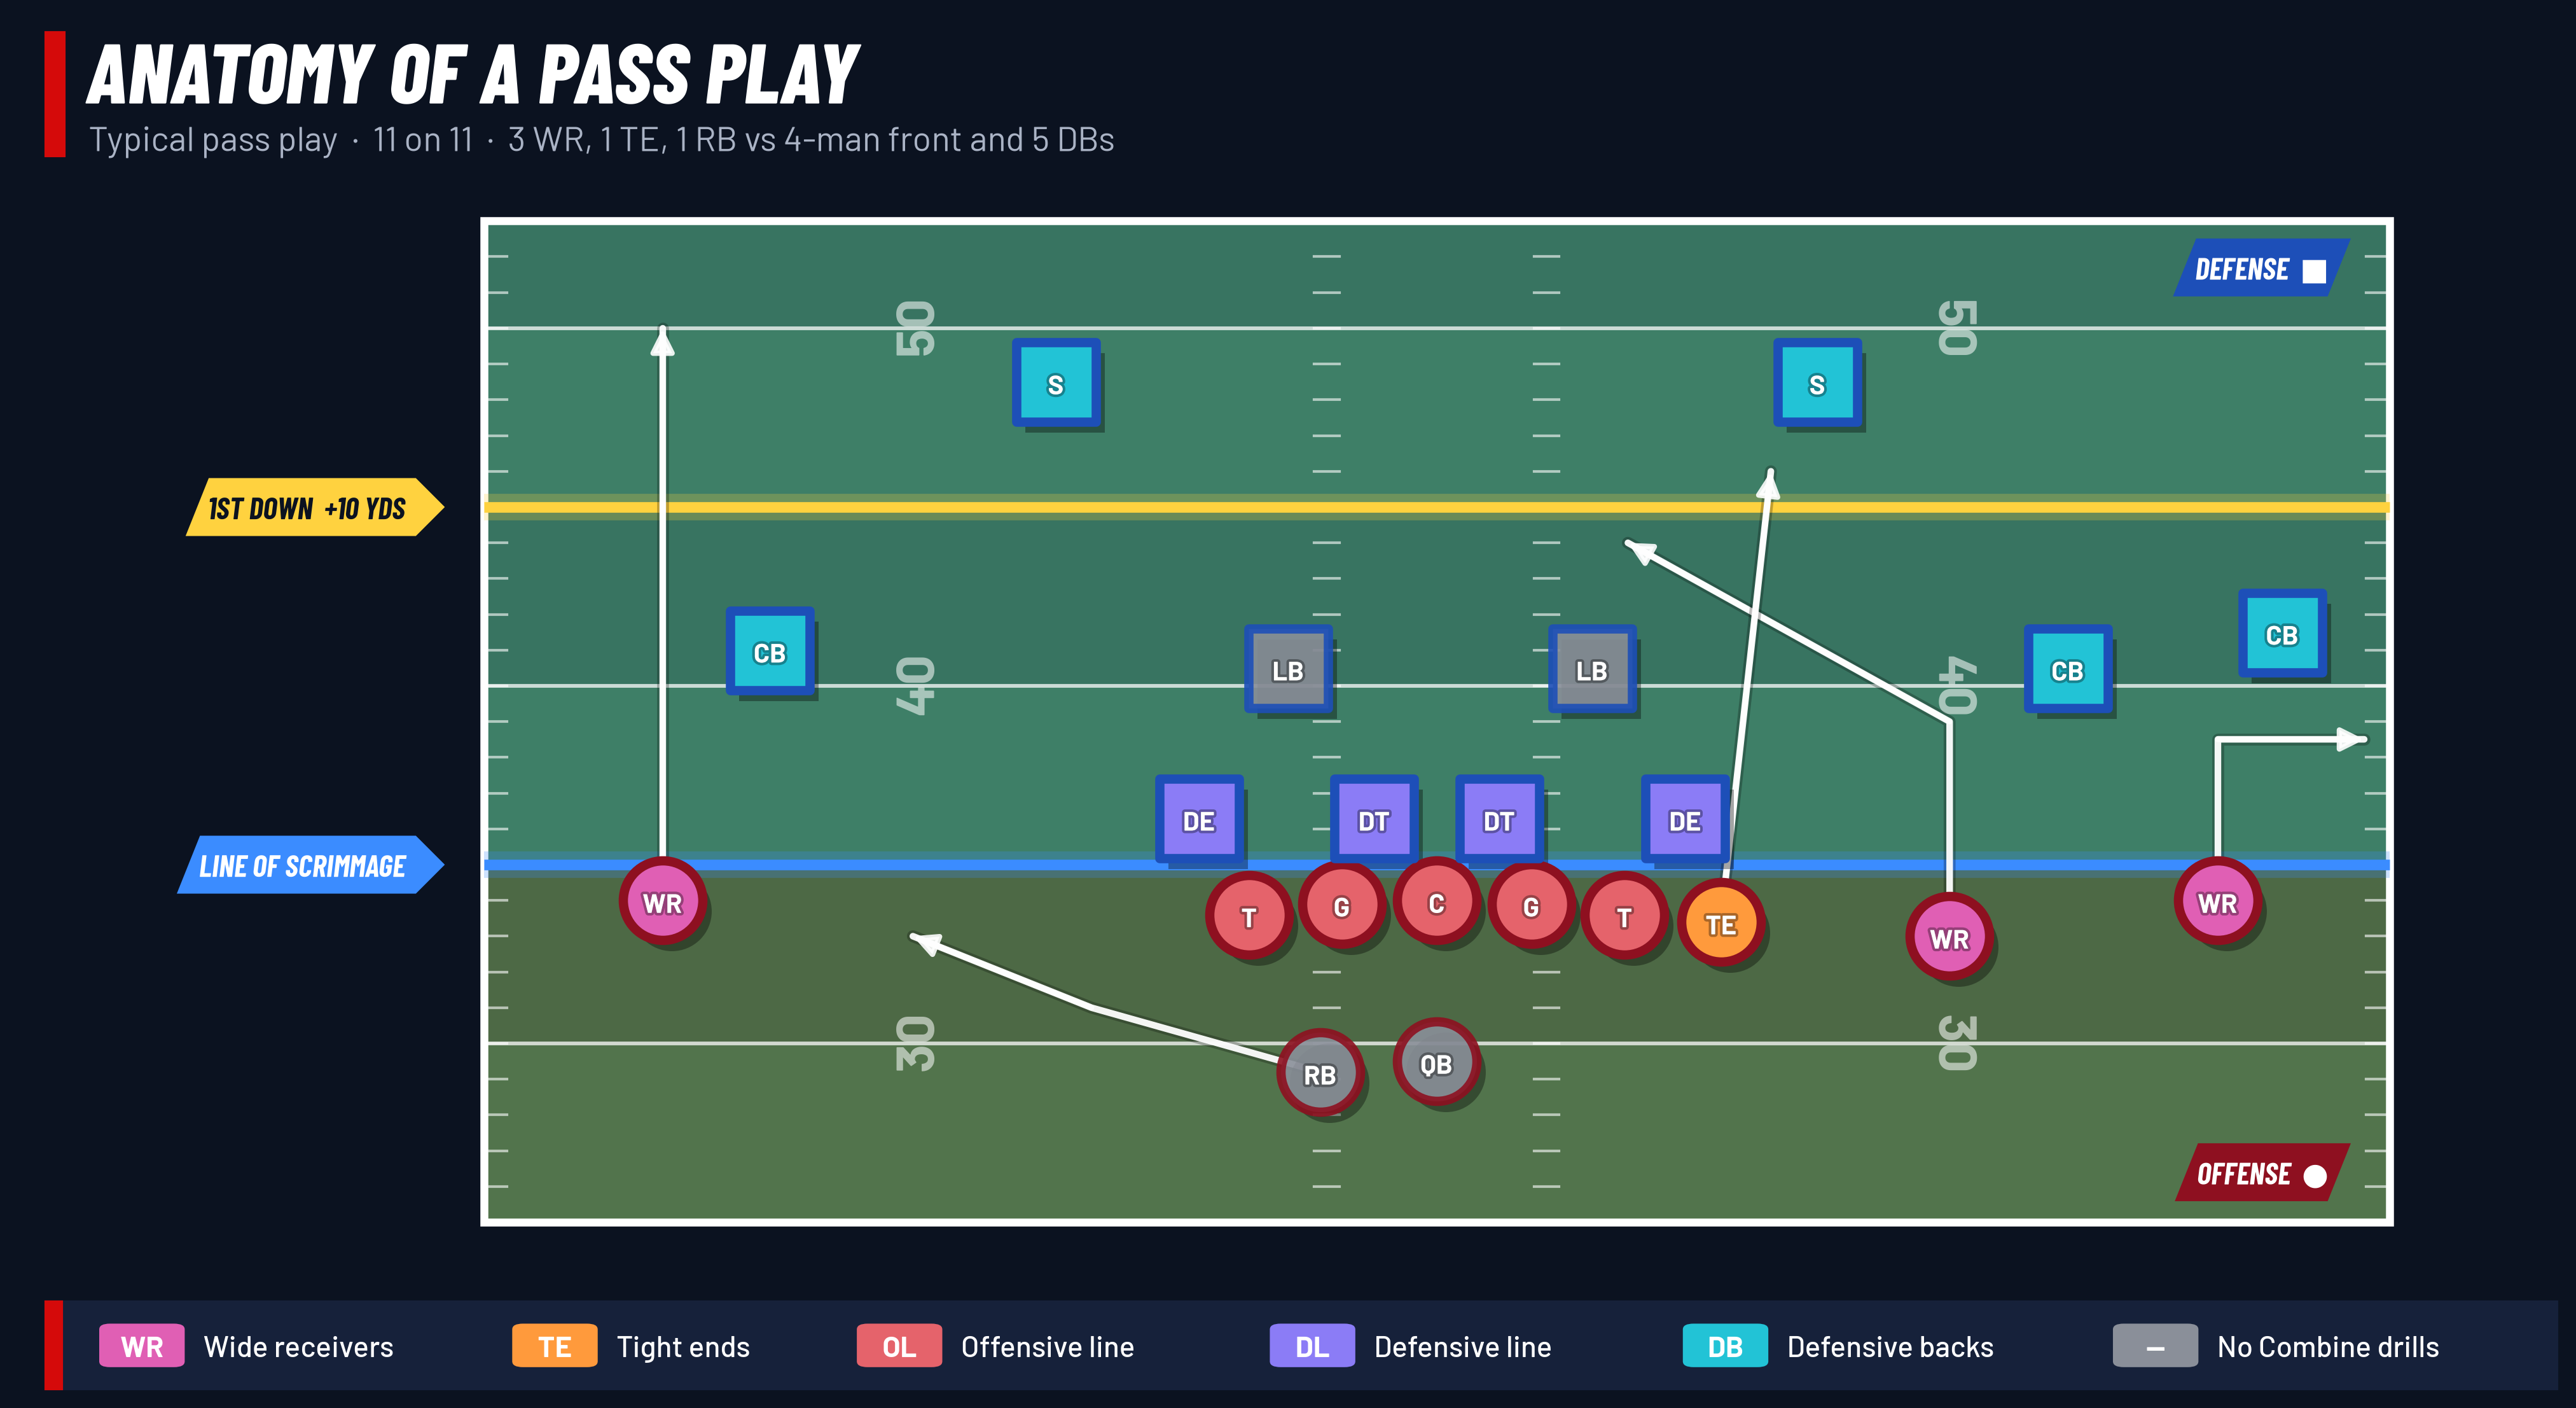

In [3]:
# (label, across-field position, yards from the line of scrimmage, group). Offense attacks upward.
OFFENSE = [
    ("C", 26.65, -1, "OL"), ("G", 24.0, -1.1, "OL"), ("G", 29.3, -1.1, "OL"), ("T", 21.4, -1.4, "OL"), ("T", 31.9, -1.4, "OL"),
    ("TE", 34.6, -1.6, "TE"), ("QB", 26.65, -5.5, None), ("RB", 23.4, -5.8, None),
    ("WR", 5, -1, "WR"), ("WR", 41, -2, "WR"), ("WR", 48.5, -1, "WR")]
DEFENSE = [
    ("DE", 20.0, 1.3, "DL"), ("DT", 24.9, 1.3, "DL"), ("DT", 28.4, 1.3, "DL"), ("DE", 33.6, 1.3, "DL"),
    ("LB", 22.5, 5.5, None), ("LB", 31, 5.5, None),
    ("CB", 8, 6, "DB"), ("CB", 44.3, 5.5, "DB"), ("CB", 50.3, 6.5, "DB"), ("S", 16, 13.5, "DB"), ("S", 37.3, 13.5, "DB")]
# Telestrator routes: (x, y) waypoints for each eligible receiver
ROUTES = [[(5, -1), (5, 15)],                                   # go
          [(41, -2), (41, 4), (32, 9)],                         # slant-in
          [(48.5, -1), (48.5, 3.5), (52.6, 3.5)],               # quick out
          [(34.6, -1.6), (36, 11)],                             # seam
          [(23.4, -5.8), (17, -4), (12, -2)]]                   # flat
Y0, Y1 = -10, 18          # visible field: 10 yards behind to 18 yards past the line of scrimmage

fig = plt.figure(figsize=(14, 7.6), facecolor=NAVY)
ax = fig.add_axes([0.02, 0.14, 0.96, 0.71])
ax.set_facecolor(NAVY)

# Turf: mowed stripes every 5 yards, sidelines, yard lines, hash marks and numbers (LOS on the offense's own 35)
for i, y in enumerate(range(Y0, Y1, 5)):
    ax.add_patch(Rectangle((0, y), 53.3, min(5, Y1 - y), color=TURF_A if i % 2 else TURF_B, zorder=0))
ax.add_patch(Rectangle((0, Y0), 53.3, Y1 - Y0, fill=False, ec="white", lw=3, zorder=1))
for y in range(Y0, Y1 + 1, 5):
    ax.plot([0, 53.3], [y, y], color="white", lw=1.4, alpha=0.75, zorder=1)
for y in range(Y0 + 1, Y1):
    for x in (0.3, 23.58, 29.73, 53.0):
        ax.plot([x - 0.35, x + 0.35], [y, y], color="white", lw=1, alpha=0.6, zorder=1)
for y in (-5, 5, 15):
    for x, rot in ((12, 90), (41.3, -90)):
        ax.text(x, y, str(35 + y), color="white", alpha=0.55, fontsize=20, fontweight="bold",
                ha="center", va="center", rotation=rot, zorder=1)

# Team colours: darker than any position colour, so the OL red never reads as "the offense"
OFFENSE_C, DEFENSE_C = "#8e1020", "#1d4fb8"
# Each team's side of the line of scrimmage, faintly tinted: offense red below, defense blue above
ax.add_patch(Rectangle((0, Y0), 53.3, -Y0, color=OFFENSE_C, alpha=0.18, lw=0, zorder=0.5))
ax.add_patch(Rectangle((0, 0), 53.3, Y1, color=DEFENSE_C, alpha=0.18, lw=0, zorder=0.5))

# Line of scrimmage and first-down line, broadcast style
glow_line(ax, [0, 53.3], [0, 0], LOS_BLUE)
glow_line(ax, [0, 53.3], [10, 10], FIRST_DOWN_YELLOW)

# Routes (drawn under the players)
for pts in ROUTES:
    xs, ys = zip(*pts)
    ax.plot(xs, ys, color="white", lw=2.5, alpha=0.95, zorder=3, solid_capstyle="round", solid_joinstyle="round",
            path_effects=[pe.withStroke(linewidth=4.5, foreground="#00000040")])
    ax.annotate("", xy=pts[-1], xytext=pts[-2], zorder=3,
                arrowprops=dict(arrowstyle="-|>", color="white", lw=2, alpha=0.9, mutation_scale=18,
                                shrinkA=0, shrinkB=0))

# Players: drop shadow + team ring (dark crimson / dark blue) + group colour (warm = offense, cool = defense)
for team, marker, ring in ((OFFENSE, "o", OFFENSE_C), (DEFENSE, "s", DEFENSE_C)):
    for label, x, y, grp in team:
        fill = POS_COLORS.get(grp, NOT_TRACKED)
        ax.scatter(x + 0.25, y - 0.3, s=900, color="black", alpha=0.35, marker=marker, linewidth=0, zorder=4)
        ax.scatter(x, y, s=900, color=fill, marker=marker, edgecolor=ring, linewidth=3.5, zorder=5,
                   alpha=1 if grp else 0.9)
        ax.text(x, y - 0.05, label, ha="center", va="center", fontsize=10, fontweight="bold",
                color="white", zorder=6, path_effects=[pe.withStroke(linewidth=2, foreground="#00000055")])

# Line tags hang in the left margin, pointing at the line they name
tag(ax, -2.2, 0.0, "LINE OF SCRIMMAGE", LOS_BLUE, ha="right", point=True)
tag(ax, -2.2, 10, "1ST DOWN  +10 YDS", FIRST_DOWN_YELLOW, NAVY, ha="right", point=True)
tag(ax, 51.6, -8.6, "OFFENSE  ●", OFFENSE_C, ha="right")
tag(ax, 51.6, 16.7, "DEFENSE  ■", DEFENSE_C, ha="right")
ax.set_xlim(-13, 54)
ax.set_ylim(Y0 - 0.4, Y1 + 0.4)
ax.set_aspect("equal")
ax.axis("off")
ax.set_anchor("W")

broadcast_header(fig, "ANATOMY OF A PASS PLAY",
                 "Typical pass play  ·  11 on 11  ·  3 WR, 1 TE, 1 RB vs 4-man front and 5 DBs")

# Lower third: one chip per Combine position group
fig.add_artist(Rectangle((0.03, 0.035), 0.94, 0.06, transform=fig.transFigure, color=NAVY_2))
fig.add_artist(Rectangle((0.03, 0.035), 0.006, 0.06, transform=fig.transFigure, color=ESPN_RED))
chips = [(g, POS_COLORS[g], POS_NAMES[g]) for g in POS_COLORS] + [("—", NOT_TRACKED, "No Combine drills")]
x = 0.05
for code, color, name in chips:
    fig.add_artist(FancyBboxPatch((x, 0.05), 0.032, 0.03, boxstyle="round,pad=0,rounding_size=0.004",
                                  transform=fig.transFigure, fc=color, ec="none"))
    fig.text(x + 0.016, 0.065, code, color="white", fontsize=11, fontweight="bold", ha="center", va="center")
    fig.text(x + 0.039, 0.065, name, color="white", fontsize=11, fontweight="medium", va="center")
    x += 0.065 + 0.0064 * len(name)
plt.show()

| Group | Side | Who's in it | What they do | Combine profile |
| :--- | :--- | :--- | :--- | :--- |
| **OL** – Offensive Line | Offense | Tackles (T), Guards (G), Center (C) | Five big blockers who protect the QB and open running lanes. The center snaps the ball. | Heaviest players; judged on strength, short area quickness and footwork |
| **TE** – Tight End | Offense | Tight Ends (and the odd FB) | Hybrid of lineman and receiver: blocks at the line or releases to catch passes. | Big *and* fast; tested on both blocking and route drills |
| **WR** – Wide Receiver | Offense | Wide Receivers | Run routes and catch passes; score many of the touchdowns. | Speed, explosiveness, clean cuts and hands |
| **DL** – Defensive Line | Defense | Defensive Ends (DE), Defensive Tackles (DT), Nose Tackles (NT), edge-rushing Outside Linebackers (OLB) | Beat blocks to stop the run and pressure the QB. Edge players sometimes drop into coverage. | Power, burst off the snap and bend around blockers |
| **DB** – Defensive Back | Defense | Cornerbacks (CB), Free & Strong Safeties (FS/SS) | Cover receivers and are the last line of defense. | Fastest defenders; backpedal, hip turns and breaking on the ball |

*Not in the Combine data:* Quarterbacks (QB), Running Backs (RB), most off-ball Linebackers (LB) and Special Teams (kicker, punter, long snapper, returners). You'll see them in game tracking, but they have no Combine drills here.

---
## 3 · Combine drills

Every year in late February / early March, ~300 of the top college prospects travel to Indianapolis for the **NFL Scouting Combine**, where they run the same set of drills in front of all 32 teams.

There are 55 drills in total, grouped by the positions that run them, with the reason each one matters on game day.

**Click a position group to expand its drills.**

In [4]:
import re

from IPython.display import HTML, display

# The 55 Combine drills by position group: (drill, category, why it matters in games, GIF in assets/)
DRILLS = {
    'Athletic testing: all positions': ("#ff0000", [
        ('40-Yard Dash', 'Timing & Speed', 'Pure straight-line speed: running away from (or chasing down) anyone in the open field.', 'FORTY_YARD_DASH_video.gif'),
        ('Vertical Jump', 'Explosiveness', 'Lower-body explosiveness: winning jump balls, and power off the snap.', 'VERTICAL_JUMP_video.gif'),
        ('Broad Jump', 'Explosiveness', 'Horizontal explosiveness: the first-step burst off the line and out of breaks.', 'BROAD_JUMP_video.gif'),
        ('Bench Press (225 lb)', 'Strength', 'Upper-body strength endurance: holding blocks and shedding blockers in the trenches.', 'BENCH_PRESS_video.gif'),
        ('3-Cone Drill', 'Agility & COD', 'Bending around tight corners at speed: rounding routes, chasing the QB, closing on the ball.', 'THREE_CONE_DRILL_video.gif'),
        ('20-Yard Short Shuttle', 'Lateral Quickness', 'Stop, plant and go the other way: the change of direction behind every cut and reaction.', 'SHORT_SHUTTLE_video.gif'),
    ]),
    'Offensive Line (OL)': (POS_COLORS["OL"], [
        ('OL Pull Drill: Fold Block Right', 'Offensive Line', 'Short, quick pull around a teammate: sealing the hole on inside runs.', 'OL_PULL_DRILL_FOLD_BLOCK_RIGHT.gif'),
        ('OL Pull Drill: Deep Short Pull Left', 'Offensive Line', 'Leaving the line at an angle and finding a target: lead blocking on gap runs.', 'OL_PULL_DRILL_DEEP_SHORT_PULL_LEFT.gif'),
        ('OL Pull Drill: Long Pull Right', 'Offensive Line', 'Running laterally in space: leading outside runs and sweeps.', 'OL_PULL_DRILL_LONG_PULL_RIGHT.gif'),
        ('Pass Protection Mirror Drill', 'Offensive Line', 'Sliding to shadow a rusher without crossing feet: keeping the QB clean.', 'PASS_PRO_MIRROR_DRILL.gif'),
        ('Screen Drill', 'Offensive Line', 'Releasing downfield and blocking in space: springing screen passes.', 'SCREEN_DRILL.gif'),
        ('Pass Rush Drop', 'Offensive Line / Pass Pro', 'Quick kick-slide into a pass set: getting depth before the edge rusher arrives.', 'PASS_RUSH_DROP.gif'),
        ('5-Yard Wave Drill (Slide & Shuffle)', 'Offensive Line', 'Reacting to direction changes while staying balanced: handling stunts and counters.', 'FIVE_YARD_WAVE_DRILL_SLIDE_AND_SHUFFLE.gif'),
    ]),
    'Tight Ends (TE)': (POS_COLORS["TE"], [
        ('Block Explosion Drill', 'TE Blocking', 'Firing out of a stance with power: winning blocks on run plays.', 'BLOCK_EXPLOSION.gif'),
        ('Corner Route', 'Route Tree', 'Breaking to the sideline at depth: stretching zones vertically.', 'CORNER_ROUTE.gif'),
        ('Flat Route (Left)', 'Route Tree', 'Releasing quickly to the flat: easy yards and play-action answers.', 'FLAT_ROUTE_LEFT.gif'),
        ('Hook Route (Right)', 'Route Tree', 'Settling in a zone gap and turning to the QB: moving the chains on 3rd down.', 'HOOK_ROUTE_RIGHT.gif'),
        ('End Zone Fade (Right)', 'Route Tree', 'Using size near the boundary: red-zone touchdowns.', 'END_ZONE_FADE_RIGHT.gif'),
        ('In Route (Left)', 'Route Tree', 'Sharp inside break in traffic: catching in front of linebackers.', 'IN_ROUTE_LEFT.gif'),
        ('Wheel Route (Left)', 'Route Tree', 'Turning upfield from the flat: exploiting slower linebackers in coverage.', 'WHEEL_ROUTE_LEFT.gif'),
    ]),
    'Wide Receivers (WR)': (POS_COLORS["WR"], [
        ('Gauntlet Catching Drill *(WR, TE, DB)*', 'Receiver / TE / DB', 'Catching at full speed with eyes on the ball: crossing routes for WR/TE, turning breakups into interceptions for DBs.', 'GAUNTLET_DRILL.gif'),
        ('Over the Shoulder Adjustment *(WR, TE)*', 'Receiver / TE', 'Tracking a deep ball and adjusting late: the catch on long and seam throws.', 'OVER_SHOULDER_ADJUST.gif'),
        ('Red Zone Fade (Right)', 'Route Tree', 'Separating in a tight space near the sideline: scoring in the red zone.', 'RED_ZONE_FADE_RIGHT.gif'),
        ('Post-Corner Route (Right)', 'Route Tree', 'Selling the post, then snapping to the corner: beating safeties deep.', 'POST_CORNER_ROUTE_RIGHT.gif'),
        ('Post-Corner Route (Left)', 'Route Tree', 'Same double move to the other side: the route works from either alignment.', 'POST_CORNER_ROUTE_LEFT.gif'),
        ('Go Route (Right)', 'Route Tree', 'Top-end speed downfield: forcing defenders to back off and respect the deep ball.', 'GO_ROUTE_RIGHT.gif'),
        ('Circus Route (Left)', 'Route Tree', 'Body control on awkward catches: turning broken plays into completions.', 'CIRCUS_ROUTE_LEFT.gif'),
        ('Slant Route (Left)', 'Route Tree', 'A fast, sharp break inside: the quick throw that beats blitzes and tight coverage.', 'SLANT_ROUTE_LEFT.gif'),
        ('Speed Out Route (Left)', 'Route Tree', 'Cutting to the sideline without slowing down: separation on timing throws.', 'SPEED_OUT_ROUTE_LEFT.gif'),
        ('Curl Route (Right)', 'Route Tree', 'Selling deep, then stopping and turning back: winning against defenders who play off.', 'CURL_ROUTE_RIGHT.gif'),
        ('Dagger Route (Left)', 'Route Tree', 'Breaking inside at depth: attacking the middle behind the linebackers.', 'DAGGER_ROUTE_LEFT.gif'),
        ('Slot Strike Route (Left)', 'Route Tree', 'Quick release and break from the slot: winning fast against nickel corners.', 'SLOT_STRIKE_ROUTE_LEFT.gif'),
        ('Comeback Route (Right)', 'Route Tree', 'Braking hard after a vertical stem: getting open when the DB is running with you.', 'COMEBACK_ROUTE_RIGHT.gif'),
        ('Slot Sail Route (Right)', 'Route Tree', 'Climbing and bending to the sideline from the slot: attacking zone holes.', 'SLOT_SAIL_ROUTE_RIGHT.gif'),
    ]),
    'Defensive Line (DL)': (POS_COLORS["DL"], [
        ('Pass Rush Drill', 'Defensive Line / EDGE', 'Beating a blocker with a rip or swim and finishing: pressures and sacks.', 'PASS_RUSH_DRILL.gif'),
        ('Run & Club Drill', 'Pass Rush', 'Winning the edge with a club move at speed: getting past tackles.', 'RUN_AND_CLUB_DRILL.gif'),
        ('Run the Hoop Drill', 'Pass Rush / Bend', 'Bending around a tight circle while leaning in: turning the corner to the QB.', 'RUN_THE_HOOP_DRILL.gif'),
        ('Short Zone Break: Forward', 'Defensive Line / Coverage Drop', 'Driving downhill out of a drop: stopping short passes underneath.', 'SHORT_ZONE_BREAK_FORWARD.gif'),
        ('Short Zone Break: Flat/Wheel', 'Defensive Line / Coverage Drop', 'Turning to run with a back out of the flat: covering wheel routes.', 'SHORT_ZONE_BREAK_FLAT_WHEEL.gif'),
        ('Short Zone Break: Inside', 'Defensive Line / Coverage Drop', 'Breaking back inside from a drop: closing on slants and crossers.', 'SHORT_ZONE_BREAK_INSIDE.gif'),
        ('Short Zone Breaks (General)', 'Defensive Line / Coverage Drop', 'Dropping into a zone and breaking on the throw: edge rushers asked to cover.', 'SHORT_ZONE_BREAKS.gif'),
        ('Front Start Wave & Lateral Reaction', 'Defensive Line / Agility', 'Reacting to a direction change from a stance: chasing runs and scrambling QBs.', 'FRONT_START_WAVE_DRILL_AND_LATERAL_REACTION.gif'),
        ('Backpedal & React', 'Defensive Line / Coverage Drop', 'Dropping back and breaking on the ball: edge players dropping into coverage.', 'BACK_PEDAL_AND_REACT.gif'),
        ('Body Control Drill', 'Footwork & Balance', 'Changing direction with a low centre of gravity: shedding blocks and redirecting.', 'BODY_CONTROL_DRILL.gif'),
        ('Four Bag Agility Drill', 'Bag Agility', 'Quick, controlled feet through traffic: stepping over bodies in the trenches.', 'FOUR_BAG_AGILITY_DRILL.gif'),
        ('Four Bag Shuffle Drill', 'Bag Agility', 'Lateral shuffle while staying square: flowing to the ball on runs.', 'FOUR_BAG_SHUFFLE_DRILL.gif'),
        ('Shuffle, Sprint & COD Drill', 'Agility & Acceleration', 'Shuffle then burst: pursuing plays that bounce outside.', 'SHUFFLE_SPRINT_AND_COD_DRILL.gif'),
        ('Wave Drill', 'Reactive Agility', 'Reactive changes of direction: tracking the ball carrier.', 'WAVE_DRILL.gif'),
    ]),
    'Defensive Backs (DB)': (POS_COLORS["DB"], [
        ('Backpedal & 45° Transition', 'Secondary', 'Opening the hips from a backpedal: carrying receivers who go deep. *(2024 reps are truncated)*', 'BACK_PEDAL_AND_TRANSITION_45_DEGREE_REACTION.gif'),
        ('Backpedal & 90° Break to Ball', 'Secondary', 'Backpedal, plant, drive sideways: breaking on out routes.', 'BACK_PEDAL_AND_90_DEGREE_BREAK_TO_BALL.gif'),
        ('Teryl Austin DB Drill #1', 'Secondary', 'Backpedal and break at an angle on cue: reading the QB and closing on the ball.', 'TERYL_AUSTIN_DRILL_1.gif'),
        ('Teryl Austin DB Drill #2', 'Secondary', 'Backpedal, turn and run: staying with receivers who stem vertically.', 'TERYL_AUSTIN_DRILL_2.gif'),
        ('Box Drill', 'Change of Direction', 'Sprint, shuffle and backpedal around a square: every movement a DB uses in one rep.', 'BOX_DRILL.gif'),
        ('W-Drill', 'Backpedal & Plant', 'Repeated backpedal-and-drive zig-zags: keeping the pedal smooth while reacting to the route.', 'W_DRILL.gif'),
        ('Line Drill', 'Speed & Conditioning', 'Straight backpedal-to-sprint transitions: speed turning to run with a receiver.', 'LINE_DRILL.gif'),
    ]),
}
GIFS = "https://raw.githubusercontent.com/juanma6610/NFL-BigDataBowl2027/main/assets/"


def md_italics(text):
    """*(...)* notes in the descriptions -> <em>."""
    return re.sub(r"\*([^*]+)\*", r"<em>\1</em>", text)


style = f"""
<style>
@import url('https://fonts.googleapis.com/css2?family=Barlow+Condensed:ital,wght@1,700&family=Barlow:wght@400;600&display=swap');
.drills {{ background: {NAVY}; color: white; font-family: Barlow, Arial, sans-serif; padding: 14px; border-radius: 4px; }}
.drills details {{ background: {NAVY_2}; margin: 8px 0; border-left: 6px solid var(--accent); }}
.drills summary {{ cursor: pointer; padding: 10px 12px; font-family: 'Barlow Condensed', 'Arial Narrow', sans-serif;
                  font-style: italic; font-weight: 700; font-size: 19px; text-transform: uppercase; letter-spacing: .3px; }}
.drills summary span {{ color: {SUBTLE}; font-family: Barlow, Arial, sans-serif; font-style: normal; font-weight: 400;
                       font-size: 14px; text-transform: none; margin-left: 8px; }}
.drills table {{ width: 100% !important; margin: 0 !important; border-collapse: collapse; background: {NAVY}; table-layout: fixed; }}
/* !important beats Jupyter's own table styling (right-aligned cells, striped and hover rows, no borders) */
.drills th {{ color: {SUBTLE} !important; text-align: left !important; font-weight: 600; font-size: 13px;
             padding: 8px 12px !important; border: none !important; border-bottom: 1px solid #22304d !important;
             background: {NAVY} !important; }}
.drills td {{ color: white; text-align: left !important; padding: 10px 12px !important; border: none !important;
             border-bottom: 1px solid #22304d !important; vertical-align: middle !important; font-size: 14px;
             background: {NAVY} !important; }}
.drills tr, .drills tr:hover, .drills tr:nth-child(odd) {{ background: {NAVY} !important; }}
.drills td.name {{ font-weight: 600; }}
.drills td.cat {{ color: {SUBTLE}; }}
.drills img {{ width: 100%; max-width: 260px; border-radius: 3px; display: block; }}
</style>"""
html = ['<div class="drills">']
for k, (group, (accent, rows)) in enumerate(DRILLS.items()):
    html.append(f'<details{" open" if k == 0 else ""} style="--accent: {accent}">'
                f'<summary>{group}<span>· {len(rows)} drills</span></summary>'
                '<table><colgroup><col style="width: 20%"><col style="width: 15%"><col style="width: 40%">'
                '<col style="width: 25%"></colgroup>'
                '<tr><th>Drill</th><th>Category</th><th>Why it matters in games</th><th>GIF</th></tr>')
    for name, cat, why, gif in rows:
        html.append(f'<tr><td class="name">{md_italics(name)}</td><td class="cat">{cat}</td><td>{md_italics(why)}</td>'
                    f'<td><img src="{GIFS}{gif}" alt="{re.sub(r"[*]", "", name)}"></td></tr>')
    html.append("</table></details>")
html.append("</div>")
display(HTML(style + "".join(html)))


Drill,Category,Why it matters in games,GIF
40-Yard Dash,Timing & Speed,Pure straight-line speed: running away from (or chasing down) anyone in the open field.,
Vertical Jump,Explosiveness,"Lower-body explosiveness: winning jump balls, and power off the snap.",
Broad Jump,Explosiveness,Horizontal explosiveness: the first-step burst off the line and out of breaks.,
Bench Press (225 lb),Strength,Upper-body strength endurance: holding blocks and shedding blockers in the trenches.,
3-Cone Drill,Agility & COD,"Bending around tight corners at speed: rounding routes, chasing the QB, closing on the ball.",
20-Yard Short Shuttle,Lateral Quickness,"Stop, plant and go the other way: the change of direction behind every cut and reaction.",
Drill,Category,Why it matters in games,GIF
OL Pull Drill: Fold Block Right,Offensive Line,"Short, quick pull around a teammate: sealing the hole on inside runs.",
OL Pull Drill: Deep Short Pull Left,Offensive Line,Leaving the line at an angle and finding a target: lead blocking on gap runs.,
OL Pull Drill: Long Pull Right,Offensive Line,Running laterally in space: leading outside runs and sweeps.,


---
## 4 · Meet the rookies
The dataset follows **one cohort**: every player from the 2023, 2024 and 2025 draft classes who was tracked at the Combine, plus how their NFL careers went.

In [5]:
import os
from pathlib import Path

import numpy as np
import pandas as pd
import polars as pl


def find_data_dir() -> Path:
    """Kaggle input folder, or a local copy (set NFL_DATA to override)."""
    if os.environ.get("NFL_DATA"):
        return Path(os.environ["NFL_DATA"])
    for root in [Path("/kaggle/input"), Path("../data/raw"), Path("data/raw")]:
        hits = sorted(root.glob("**/combine_results.csv")) if root.exists() else []
        if hits:
            return hits[0].parent
    raise FileNotFoundError("Add the nfl-big-data-bowl-2027 competition data to this notebook.")


def read(name: str) -> pl.DataFrame:
    return pl.read_csv(DATA / f"{name}.csv", null_values="NA", infer_schema_length=100_000)


DATA = find_data_dir()
players = read("players")
combine = read("combine_results")
career = read("player_career_successes")

# One row per rookie: bio + draft info, Combine results, and NFL career outcomes
cohort = (players.join(combine.select(pl.exclude("draft_year")), on="nfl_id")
          .join(career, on="nfl_id", how="left")
          .rename({"combine_position": "pos"}))
POS_ORDER = ["WR", "TE", "OL", "DL", "DB"]
print(f"Data folder: {DATA}  ·  {cohort.height} rookies")

Data folder: ../data/raw/nfl-big-data-bowl-2027  ·  510 rookies


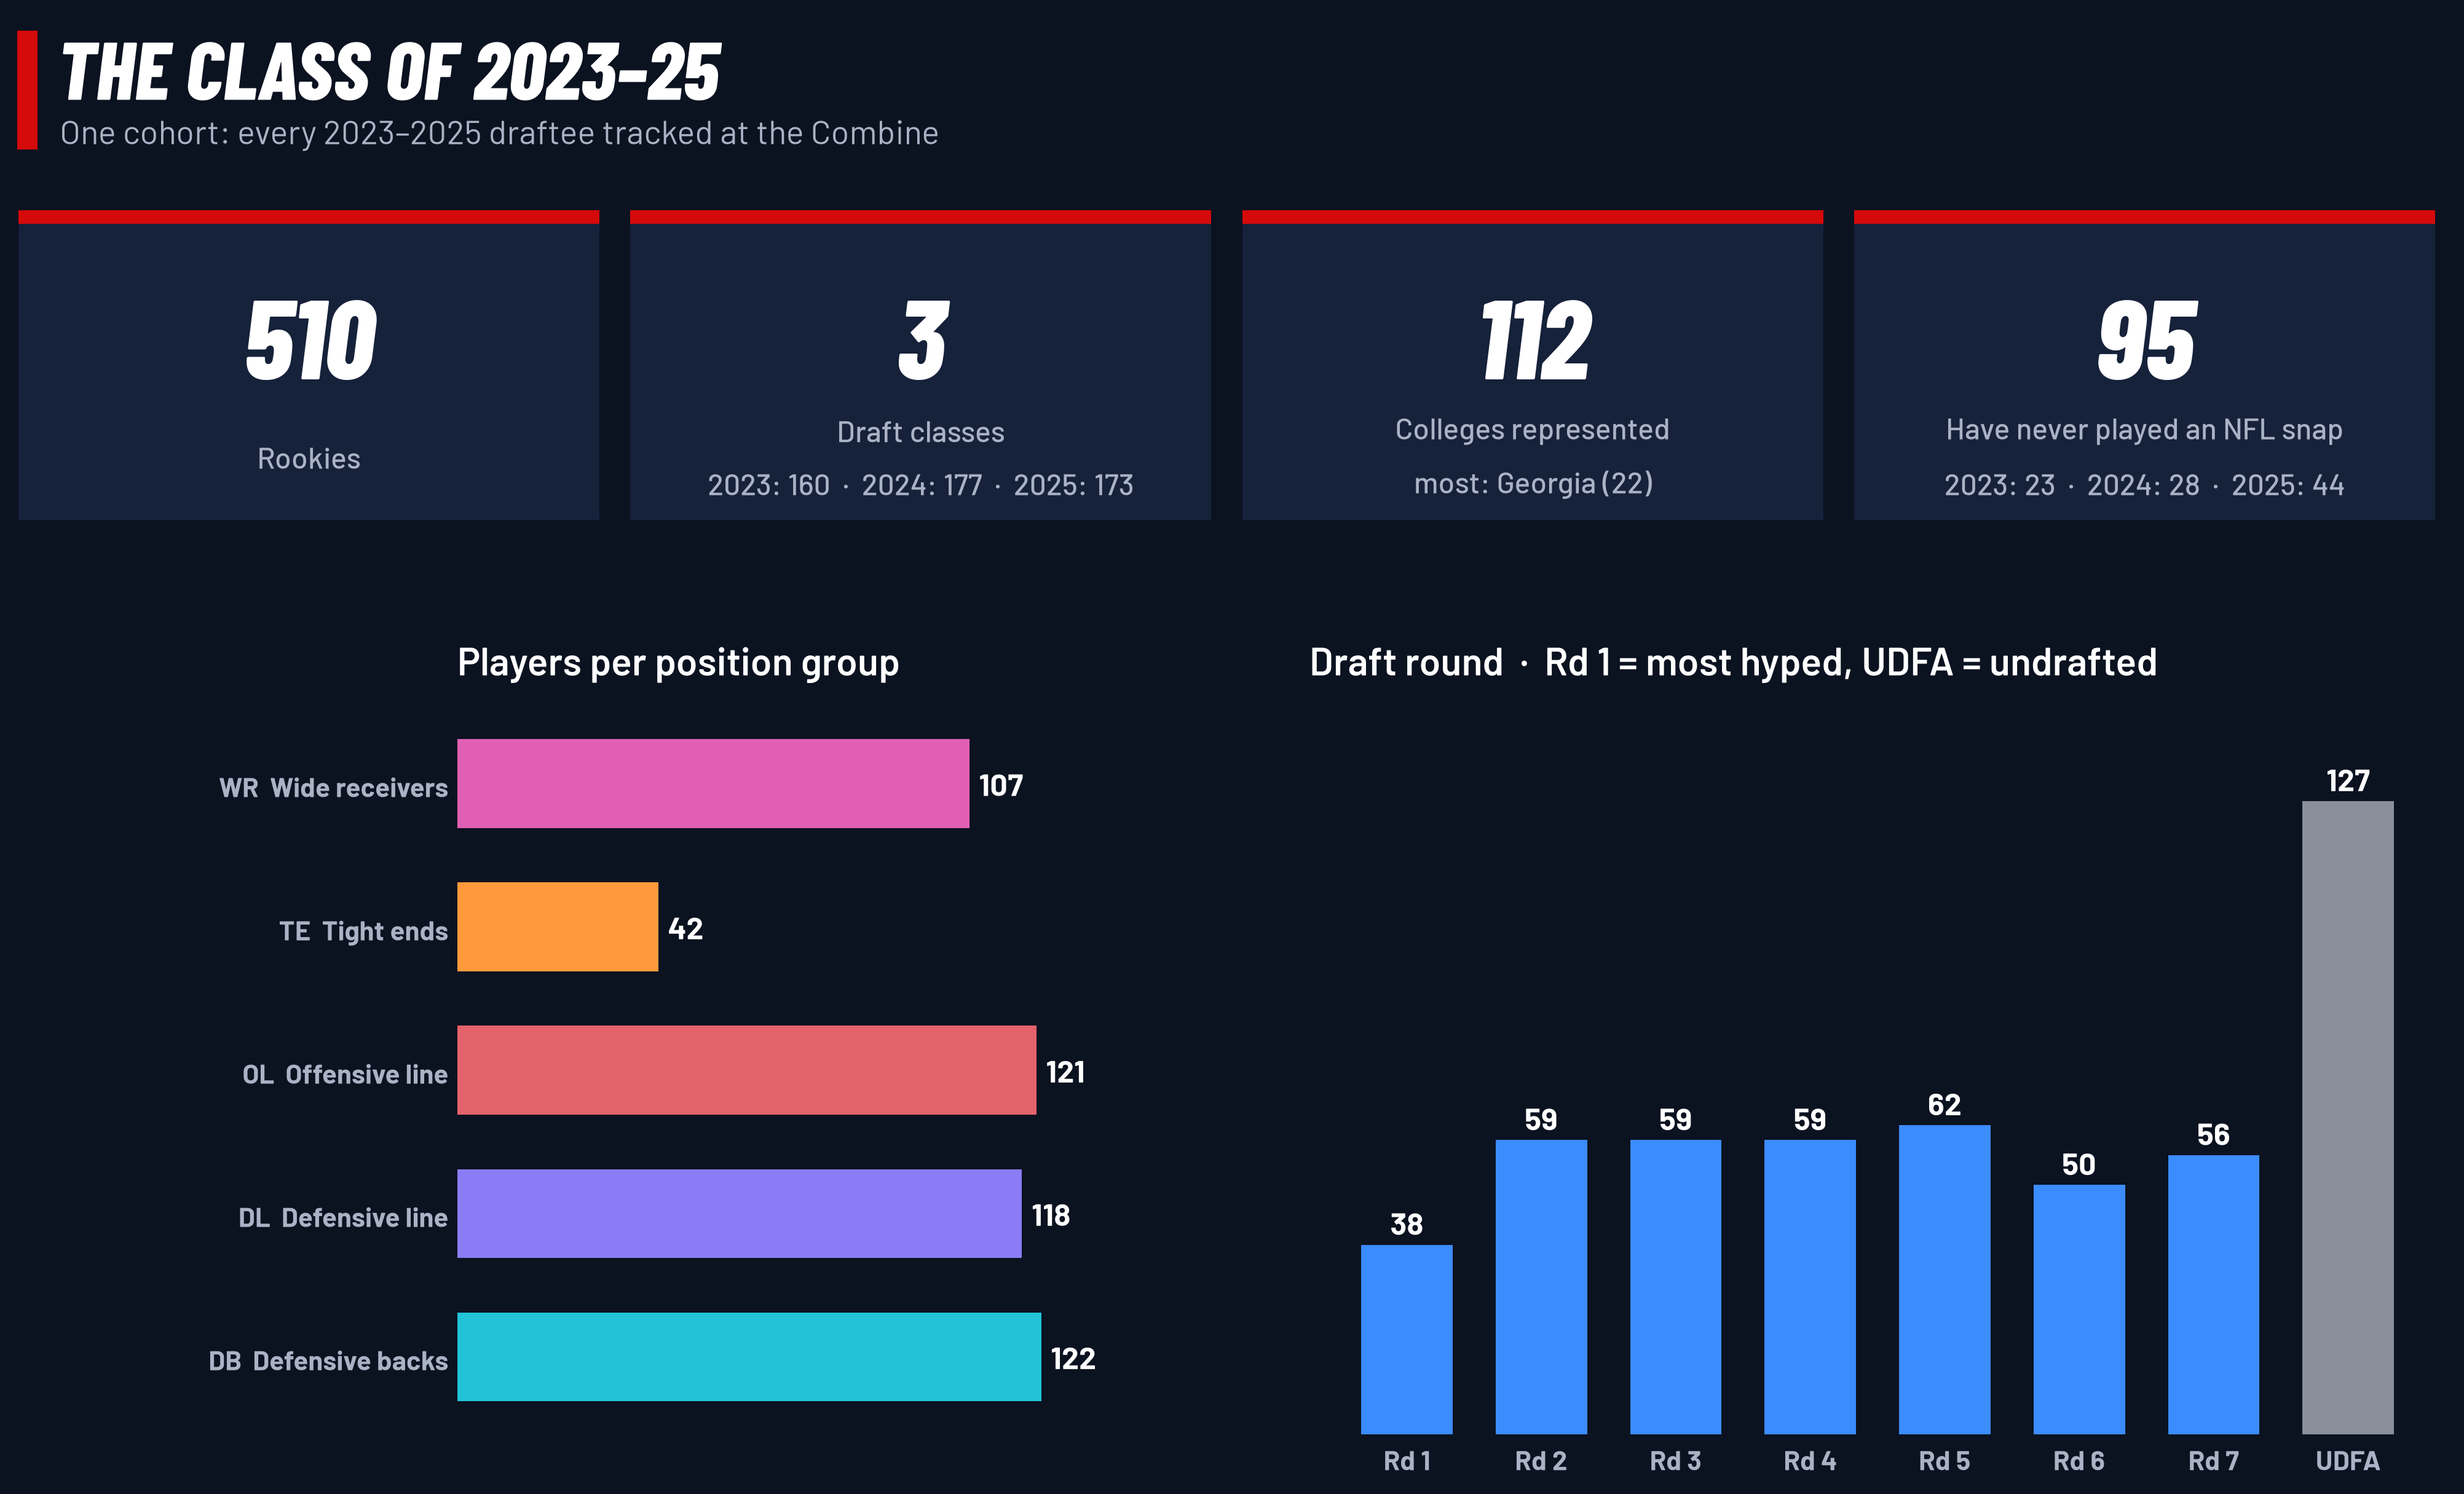

In [6]:
per_class = cohort.group_by("draft_year").len().sort("draft_year")
top_college, top_college_n = cohort["college_name"].value_counts(sort=True).row(0)
# "Never played" = zero offensive, defensive and special-teams snaps (some dressed for games but never got on the field)
no_snaps = cohort.filter(pl.sum_horizontal(pl.col("career_offensive_snaps", "career_defensive_snaps",
                                                  "career_special_teams_snaps").fill_null(0)) == 0)
tiles = [(f"{cohort.height}", "Rookies"),
         ("3", "Draft classes\n" + "  ·  ".join(f"{y}: {n}" for y, n in per_class.iter_rows())),
         (f"{cohort['college_name'].n_unique()}", f"Colleges represented\nmost: {top_college} ({top_college_n})"),
         (f"{no_snaps.height}", "Have never played an NFL snap\n" + "  ·  ".join(
             f"{y}: {n}" for y, n in no_snaps.group_by("draft_year").len().sort("draft_year").iter_rows()))]

fig = plt.figure(figsize=(14, 8.4), facecolor=NAVY)
broadcast_header(fig, "THE CLASS OF 2023–25", "One cohort: every 2023–2025 draftee tracked at the Combine",
                 top=0.975, height=0.075)

# Stat tiles
for i, (big, small) in enumerate(tiles):
    ax = fig.add_axes([0.03 + i * 0.237, 0.66, 0.225, 0.2])
    ax.add_patch(Rectangle((0, 0), 1, 1, color=NAVY_2, transform=ax.transAxes))
    ax.add_patch(Rectangle((0, 0.96), 1, 0.04, color=ESPN_RED, transform=ax.transAxes))
    ax.text(0.5, 0.6, big, ha="center", va="center", fontsize=44, fontweight="heavy", fontstyle="italic",
            family=DISPLAY, color="white", transform=ax.transAxes)
    ax.text(0.5, 0.2, small, ha="center", va="center", fontsize=11.5, fontweight="medium", color=SUBTLE,
            linespacing=1.5, transform=ax.transAxes)
    ax.axis("off")


def panel(rect, title):
    ax = fig.add_axes(rect)
    ax.set_facecolor(NAVY)
    ax.set_title(title, loc="left", color="white", fontsize=15, fontweight="semibold", pad=12)
    for side in ax.spines.values():
        side.set_visible(False)
    ax.tick_params(colors=SUBTLE, length=0, labelsize=10.5)
    return ax


# Players per position group
a1 = panel([0.2, 0.07, 0.26, 0.47], "Players per position group")
counts = cohort.group_by("pos").len().to_pandas().set_index("pos").loc[POS_ORDER[::-1]]
a1.barh(range(5), counts["len"], color=[POS_COLORS[p] for p in counts.index], height=0.62)
for y, v in enumerate(counts["len"]):
    a1.text(v + 2, y, v, va="center", color="white", fontsize=12, fontweight="bold")
a1.set_yticks(range(5), [f"{p}  {POS_NAMES[p]}" for p in counts.index], fontweight="bold")
a1.set_xticks([])
a1.set_xlim(0, counts["len"].max() * 1.15)

# Draft round
a2 = panel([0.53, 0.07, 0.44, 0.47], "Draft round  ·  Rd 1 = most hyped, UDFA = undrafted")
rounds = (cohort.with_columns(r=pl.col("draft_round").cast(pl.String).fill_null("UDFA"))
          .group_by("r").len().to_pandas().set_index("r").reindex([*map(str, range(1, 8)), "UDFA"]).fillna(0))
a2.bar(range(len(rounds)), rounds["len"], color=[LOS_BLUE] * 7 + [NOT_TRACKED], width=0.68)
for x, v in enumerate(rounds["len"]):
    a2.text(x, v + 2, int(v), ha="center", color="white", fontsize=12, fontweight="bold")
a2.set_xticks(range(len(rounds)), [f"Rd {r}" if r != "UDFA" else r for r in rounds.index], fontweight="bold")
a2.set_yticks([])
a2.set_ylim(0, rounds["len"].max() * 1.15)
plt.show()

### Built for the job
Each dot is one rookie, measured at the Combine. Height and weight sort players into **three body types** almost perfectly:

- **Skill** (WR + DB): about 6'0", 195 lb
- **Hybrid** (TE + edge rushers): about 6'4", 250 lb
- **Big** (OL + interior DL): about 6'4", 310 lb

Inside a body type, though, a tape measure can't tell positions apart: a receiver and a cornerback are built the same. Adding hand size, arm length, wingspan, the stopwatch drills or the NGS scores doesn't fix that either. **Telling them apart is what the drill tracking data is for.**

> The `DL` group mixes two body types: edge rushers (DE/OLB, ~258 lb) and interior linemen (DT/NT, ~307 lb). Use `nfl_position` from `players.csv` to split them before modelling.

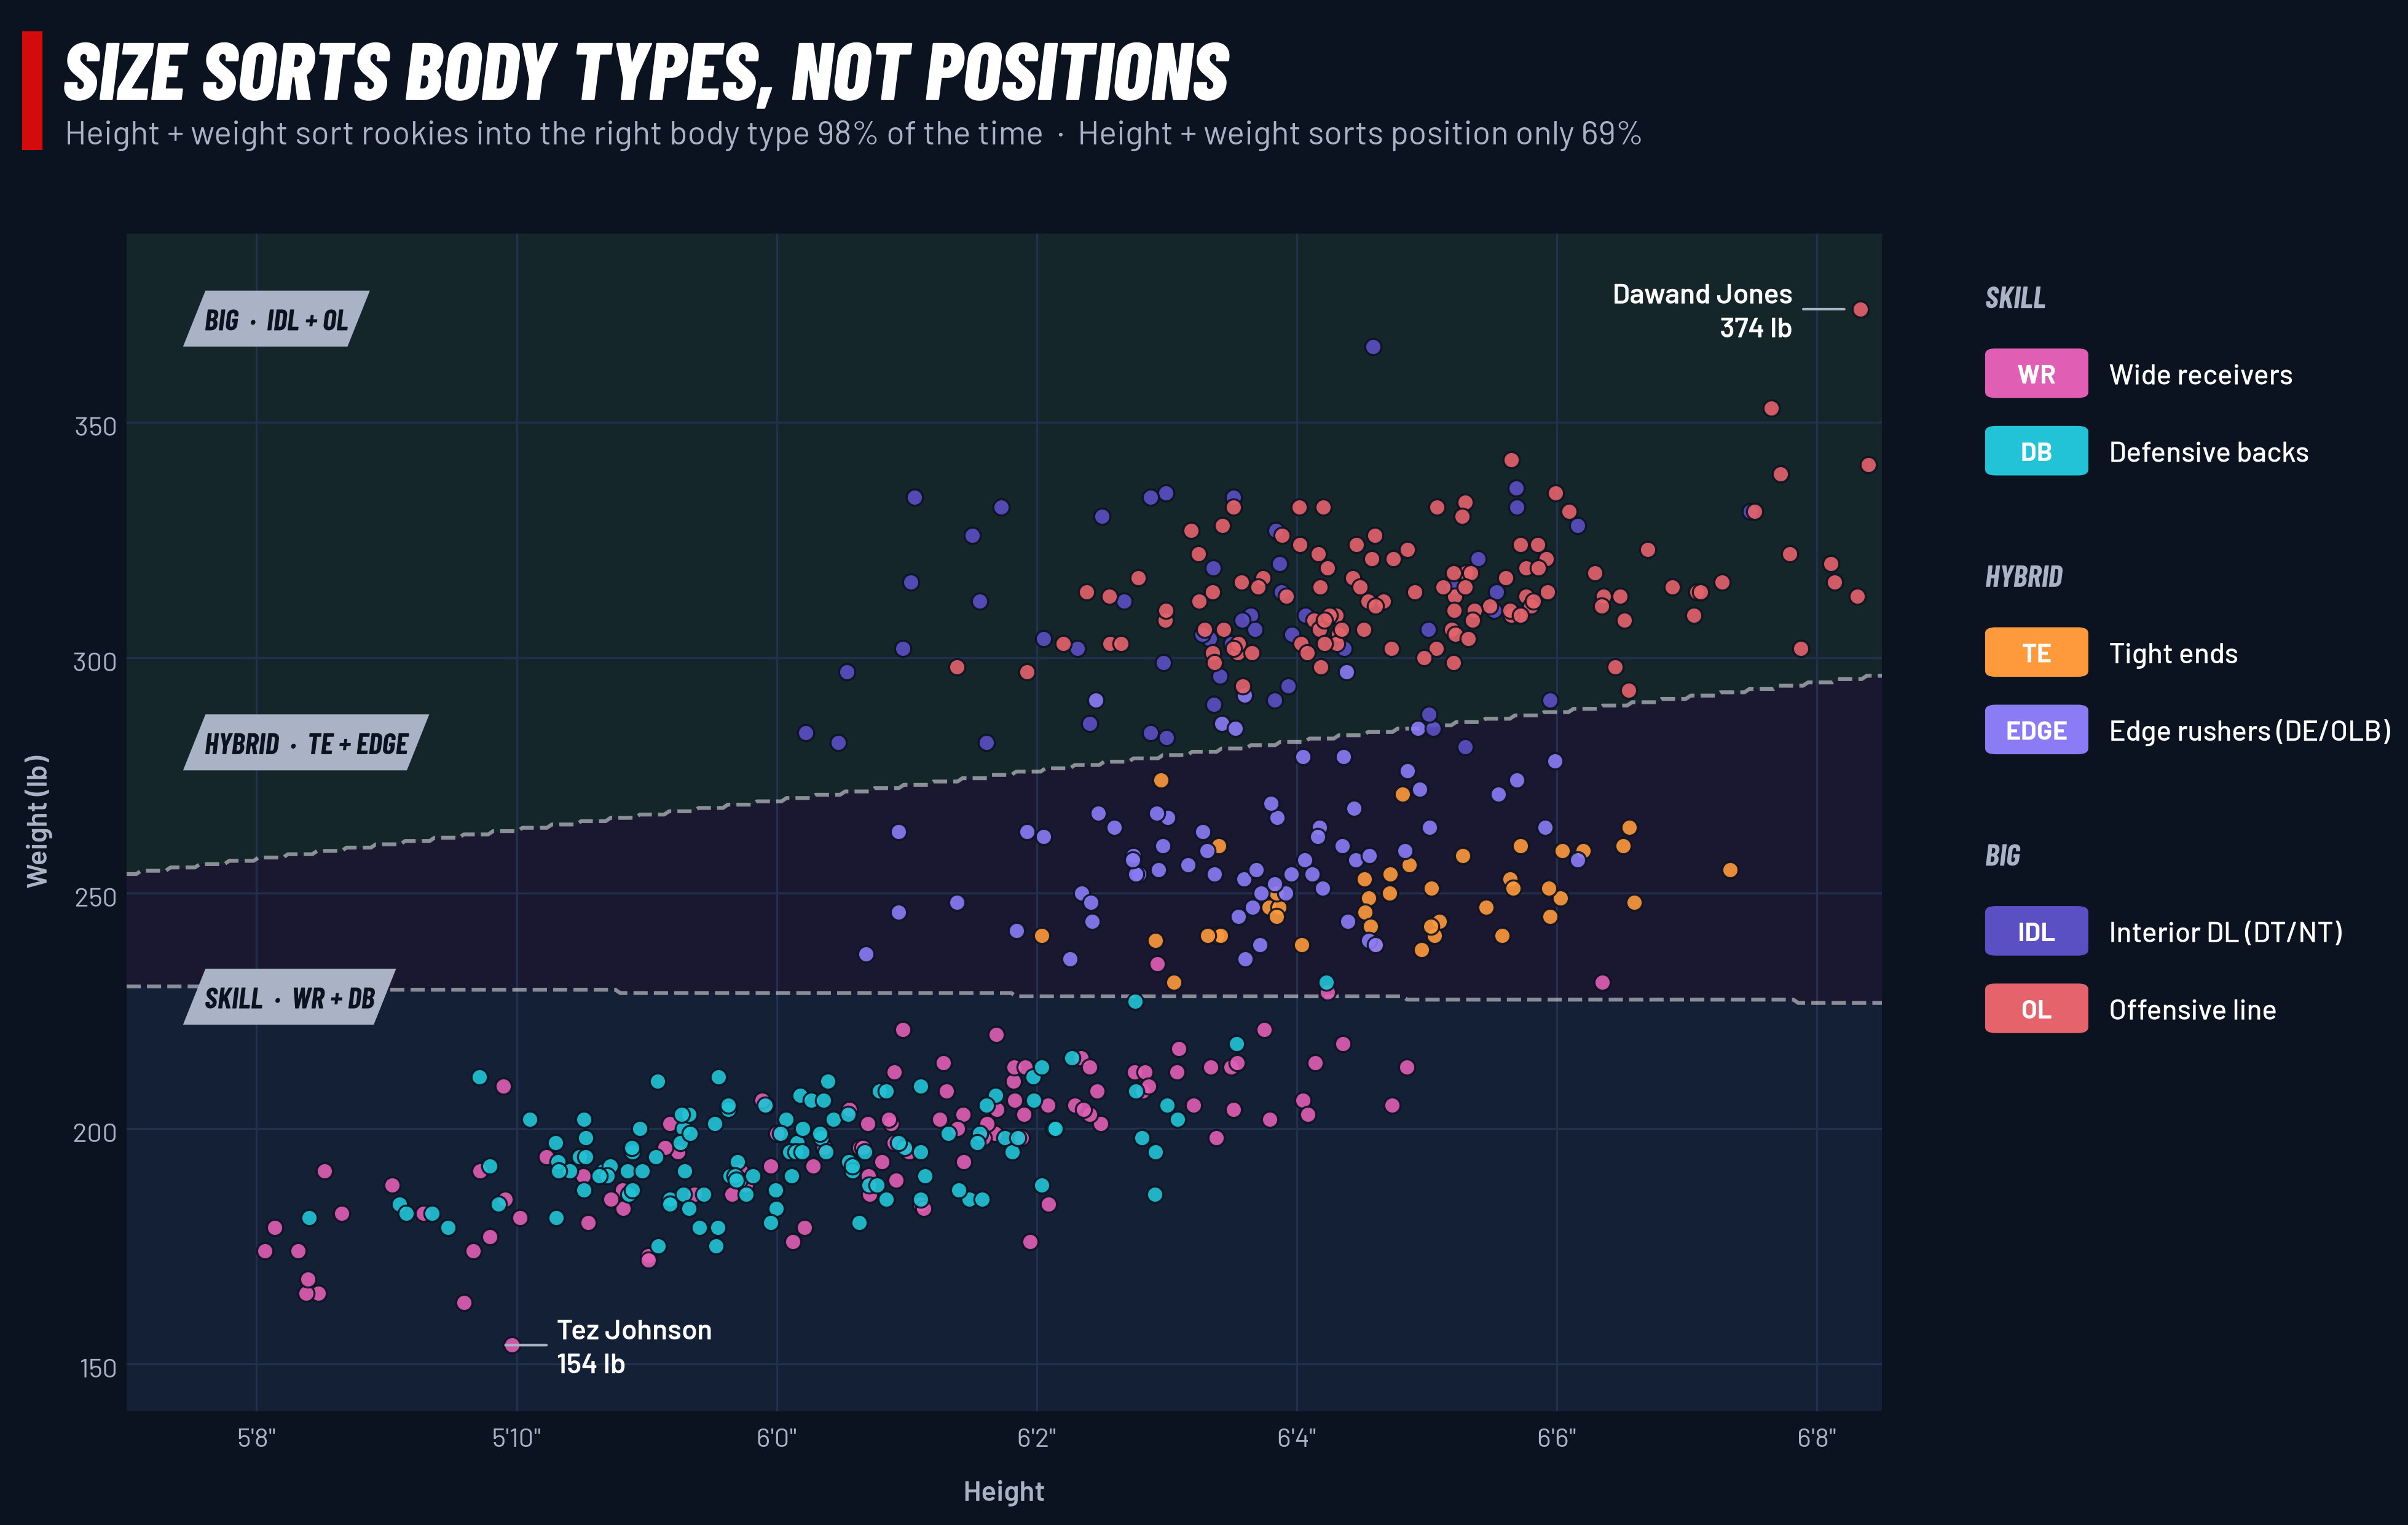

In [7]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Split the DL group by NFL position: edge rushers and interior linemen have very different bodies
cb = cohort.select("display_name", "pos", "nfl_position", "combine_height", "combine_weight").to_pandas()
cb["group"] = cb.pos.where(cb.pos != "DL", np.where(cb.nfl_position.isin(["DE", "OLB"]), "EDGE", "IDL"))
GROUP_COLORS = {"WR": POS_COLORS["WR"], "DB": POS_COLORS["DB"], "TE": POS_COLORS["TE"],
                "EDGE": POS_COLORS["DL"], "IDL": "#5b4fc4", "OL": POS_COLORS["OL"]}
GROUP_NAMES = {"WR": "Wide receivers", "DB": "Defensive backs", "TE": "Tight ends",
               "EDGE": "Edge rushers (DE/OLB)", "IDL": "Interior DL (DT/NT)", "OL": "Offensive line"}
BODY_TYPES = {"SKILL": ["WR", "DB"], "HYBRID": ["TE", "EDGE"], "BIG": ["IDL", "OL"]}
cb["body"] = cb.group.map({g: b for b, gs in BODY_TYPES.items() for g in gs})

# How well do height + weight alone sort players? (5-fold cross-validated linear classifier)
X = cb[["combine_height", "combine_weight"]]
cv = StratifiedKFold(5, shuffle=True, random_state=0)
acc_body = cross_val_score(LinearDiscriminantAnalysis(), X, cb.body, cv=cv).mean()
acc_pos = cross_val_score(LinearDiscriminantAnalysis(), X, cb.pos, cv=cv).mean()

fig = plt.figure(figsize=(14, 8.4), facecolor=NAVY)
broadcast_header(fig, "SIZE SORTS BODY TYPES, NOT POSITIONS",
                 f"Height + weight sort rookies into the right body type {acc_body:.0%} of the time  ·  "
                 f"Height + weight sorts position only {acc_pos:.0%}", top=0.97, height=0.075)
ax = fig.add_axes([0.07, 0.08, 0.68, 0.76])
ax.set_facecolor(NAVY)
for side in ax.spines.values():
    side.set_visible(False)
ax.grid(color="#22304d", lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=SUBTLE, length=0, labelsize=10.5)

# Body-type zones: shade the region where the classifier would call each body type
lda = LinearDiscriminantAnalysis().fit(X.values, cb.body)
hh, ww = np.meshgrid(np.linspace(67, 82, 400), np.linspace(140, 420, 400))
zone = pd.Series(lda.predict(np.c_[hh.ravel(), ww.ravel()])).map({b: i for i, b in enumerate(BODY_TYPES)})
zone = zone.values.reshape(hh.shape)
ax.contourf(hh, ww, zone, levels=[-0.5, 0.5, 1.5, 2.5], colors=["#132036", "#1a1830", "#14262a"], zorder=0)
ax.contour(hh, ww, zone, levels=[0.5, 1.5], colors="white", alpha=0.5, linewidths=1.5,
           linestyles="dashed", zorder=1)
LABEL_AT = {"SKILL": (67.6, 228), "HYBRID": (67.6, 282), "BIG": (67.6, 372)}
for body, groups in BODY_TYPES.items():
    tag(ax, *LABEL_AT[body], f"{body}  ·  {' + '.join(groups)}", SUBTLE, NAVY)

rng = np.random.default_rng(7)
for g, color in GROUP_COLORS.items():
    d = cb[cb.group == g]
    ax.scatter(d.combine_height + rng.uniform(-0.12, 0.12, len(d)), d.combine_weight, s=40, color=color,
               alpha=0.9, edgecolor=NAVY, linewidth=0.8, zorder=3)

# Call out the heaviest (label to the left) and lightest (label to the right) rookie
for (_, r), dx in zip(pd.concat([cb.nlargest(1, "combine_weight"), cb.nsmallest(1, "combine_weight")]).iterrows(),
                      (-22, 22)):
    ax.annotate(f"{r.display_name}\n{r.combine_weight:.0f} lb", (r.combine_height, r.combine_weight),
                xytext=(dx, 0), textcoords="offset points", fontsize=11, fontweight="semibold", color="white",
                ha="right" if dx < 0 else "left", va="center", zorder=5,
                arrowprops=dict(arrowstyle="-", color=SUBTLE))
ticks = range(68, 82, 2)
ax.set_xticks(ticks, [f"{t // 12}'{t % 12}\"" for t in ticks])
ax.set_xlim(67, 80.5)
ax.set_ylim(140, 390)
ax.set_xlabel("Height", color=SUBTLE, fontweight="semibold", labelpad=8)
ax.set_ylabel("Weight (lb)", color=SUBTLE, fontweight="semibold", labelpad=8)

# Legend as a broadcast side panel, grouped by body type
y = 0.8
for body, groups in BODY_TYPES.items():
    fig.text(0.79, y, body, color=SUBTLE, fontsize=12, fontweight="bold", fontstyle="italic", family=DISPLAY, va="center")
    y -= 0.05
    for g in groups:
        fig.add_artist(FancyBboxPatch((0.79, y - 0.016), 0.04, 0.032, boxstyle="round,pad=0,rounding_size=0.004",
                                      transform=fig.transFigure, fc=GROUP_COLORS[g], ec="none"))
        fig.text(0.81, y, g, color="white", fontsize=10, fontweight="bold", ha="center", va="center")
        fig.text(0.838, y, GROUP_NAMES[g], color="white", fontsize=11, fontweight="medium", va="center")
        y -= 0.05
    y -= 0.03
plt.show()

### How fast does each position run?

Every position group lines up for a 40-yard dash. Each runner shows the group's **median time at each yard mark** (using each player's best attempt), replayed from the 10 Hz Combine tracking.

> **Tracking starts a little late on most reps**, so tracked 40 times run about 0.3 s slower than the official `forty` in `combine_results.csv`, and a few reps are off by much more. The order of the groups holds, but don't compare tracked and official times directly. For clean speed numbers, time from the 10-yard mark onwards or use `forty - ten_yd_split`.

In [8]:
import plotly.graph_objects as go
from IPython.display import HTML, display

display(HTML("<style>@import url('https://fonts.googleapis.com/css2?family=Barlow+Condensed:ital,wght@1,700;1,800"
             "&family=Barlow:wght@400;600&display=swap');</style>"))
WEB_DISPLAY, WEB_BODY = "Barlow Condensed, Arial Narrow, sans-serif", "Barlow, Arial, sans-serif"

# 40-yard dash tracking: seconds and yards since tracking started, per rep
forty = (read("combine_tracking")
         .filter((pl.col("entity_type") == "PLAYER") & (pl.col("drill_name") == "FORTY_YARD_DASH"))
         .with_columns(pl.col("time").str.to_datetime(time_unit="ms"))
         .sort("event_id", "time")
         .with_columns(t=(pl.col("time") - pl.col("time").first()).over("event_id").dt.total_milliseconds() / 1000,
                       dist=(pl.col("x") - pl.col("x").first()).over("event_id"))
         .to_pandas())
forty["group"] = forty.nfl_id.map(dict(zip(cohort["nfl_id"], cb.group)))   # DL split into EDGE / IDL

# Time at each yard mark for every rep (a few reps stop just short of 40: extend them at their final speed)
DIST = np.arange(0, 40.25, 0.25)
splits = {}
for eid, r in forty.groupby("event_id"):
    times = np.interp(DIST, r.dist, r.t)
    past = DIST > r.dist.iloc[-1]
    times[past] = r.t.iloc[-1] + (DIST[past] - r.dist.iloc[-1]) / r.s.iloc[-1]
    splits[eid] = (r.nfl_id.iloc[0], r.group.iloc[0], times)

# Each player's best rep, then the median player of each group at every yard mark
best = {}
for nfl_id, group, times in splits.values():
    if nfl_id not in best or times[-1] < best[nfl_id][1][-1]:
        best[nfl_id] = (group, times)
runs = {g: np.median([tm for grp, tm in best.values() if grp == g], axis=0) for g in GROUP_COLORS}
order = sorted(runs, key=lambda g: -runs[g][-1])          # fastest in the top lane
# The race stops when the winner crosses the line; the clock keeps running until every group's
# (hypothetical) finish time has come up, and each time appears at that moment
t_win = min(r[-1] for r in runs.values())
T = np.round(np.arange(0, max(r[-1] for r in runs.values()) + 0.3, 0.1), 1)


def frame(t):
    y = list(range(len(order)))
    return [go.Scatter(x=[np.interp(min(t, t_win), runs[g], DIST) for g in order], y=y, mode="markers+text",
                       marker=dict(size=40, color=[GROUP_COLORS[g] for g in order], line=dict(color="white", width=2.5)),
                       text=order, textfont=dict(color="white", size=11, family=WEB_DISPLAY)),
            go.Scatter(x=[41.2] * len(order), y=y, mode="text", textposition="middle right",
                       text=[f"<b>{runs[g][-1]:.2f}s</b>" if t >= runs[g][-1] else "" for g in order],
                       textfont=dict(color="white", size=16, family=WEB_DISPLAY)),
            go.Scatter(x=[45], y=[len(order) - 0.05], mode="text", textposition="middle left",
                       text=[f"<b>CLOCK  {t:.1f}s</b>"], textfont=dict(color=FIRST_DOWN_YELLOW, size=20, family=WEB_DISPLAY))]


top = len(order) - 0.5
stripes = [dict(type="rect", x0=x, x1=x + 5, y0=-0.5, y1=top, line_width=0, layer="below",
                fillcolor=TURF_A if x % 10 else TURF_B) for x in range(-5, 45, 5)]
lines = [dict(type="line", x0=x, x1=x, y0=-0.5, y1=top, layer="below",
              line=dict(color=ESPN_RED if x == 40 else "rgba(255,255,255,0.55)", width=5 if x == 40 else 1.5))
         for x in range(0, 41, 5)]

race = go.Figure(
    data=frame(0), frames=[go.Frame(data=frame(t), name=str(t)) for t in T],
    layout=dict(
        title=dict(text="<b><i>THE 40-YARD RACE</i></b><br><span style='font-size:14px;color:#aab3c5;font-family:Barlow,Arial,sans-serif'>"
                        "Median time of each group at every yard mark, from Combine tracking at 10 Hz  ·  real time</span>",
                   x=0.02, y=0.94, yanchor="top", font=dict(color="white", size=32, family=WEB_DISPLAY)),
        paper_bgcolor=NAVY, plot_bgcolor=NAVY, height=540, margin=dict(l=210, r=30, t=100, b=70),
        font=dict(color="white", family=WEB_BODY), showlegend=False, shapes=stripes + lines, hovermode=False,
        xaxis=dict(range=[-5, 45], tickvals=[0, 10, 20, 30, 40], ticktext=["START", "10", "20", "30", "FINISH"],
                   showgrid=False, zeroline=False, fixedrange=True),
        yaxis=dict(range=[-0.5, top + 0.8], tickvals=list(range(len(order))), showgrid=False, zeroline=False,
                   ticktext=[f"<b>{GROUP_NAMES[g].upper()}</b>" for g in order], fixedrange=True,
                   tickfont=dict(family=WEB_DISPLAY, size=15)),
        updatemenus=[dict(type="buttons", x=0, y=-0.08, xanchor="left", yanchor="top", direction="right", showactive=False,
                          bgcolor=NAVY_2, bordercolor=ESPN_RED, font=dict(color="white"), buttons=[
            dict(label="▶  RUN", method="animate",
                 args=[None, dict(frame=dict(duration=100, redraw=False), fromcurrent=True,
                                  transition=dict(duration=0))]),
            dict(label="↺  RESET", method="animate",
                 args=[[str(T[0])], dict(mode="immediate", frame=dict(duration=0, redraw=False),
                                         transition=dict(duration=0))])])]))
race.show()

---
## 5 · Sundays: GameTime data
For the same rookies we have their real NFL snaps: `player_play.csv` (one row per player per play, with stats like separation or pressure)
and `game_tracking_{2023,2024,2025}.csv` (the same 10 Hz tracking, during games).

### What does "playing well" mean in the data?
There are two levels to the answer, and the competition is really about both.

**1. Playing at all.** `player_career_successes.csv` counts every rookie's snaps, starts, Pro Bowls and All-Pro selections. Snaps are the most useful: everyone has them, even the players who never got on the field. Career totals depend on how long a player has been in the league (the 2023 class has had three seasons, the 2025 class one), so divide by seasons before comparing.

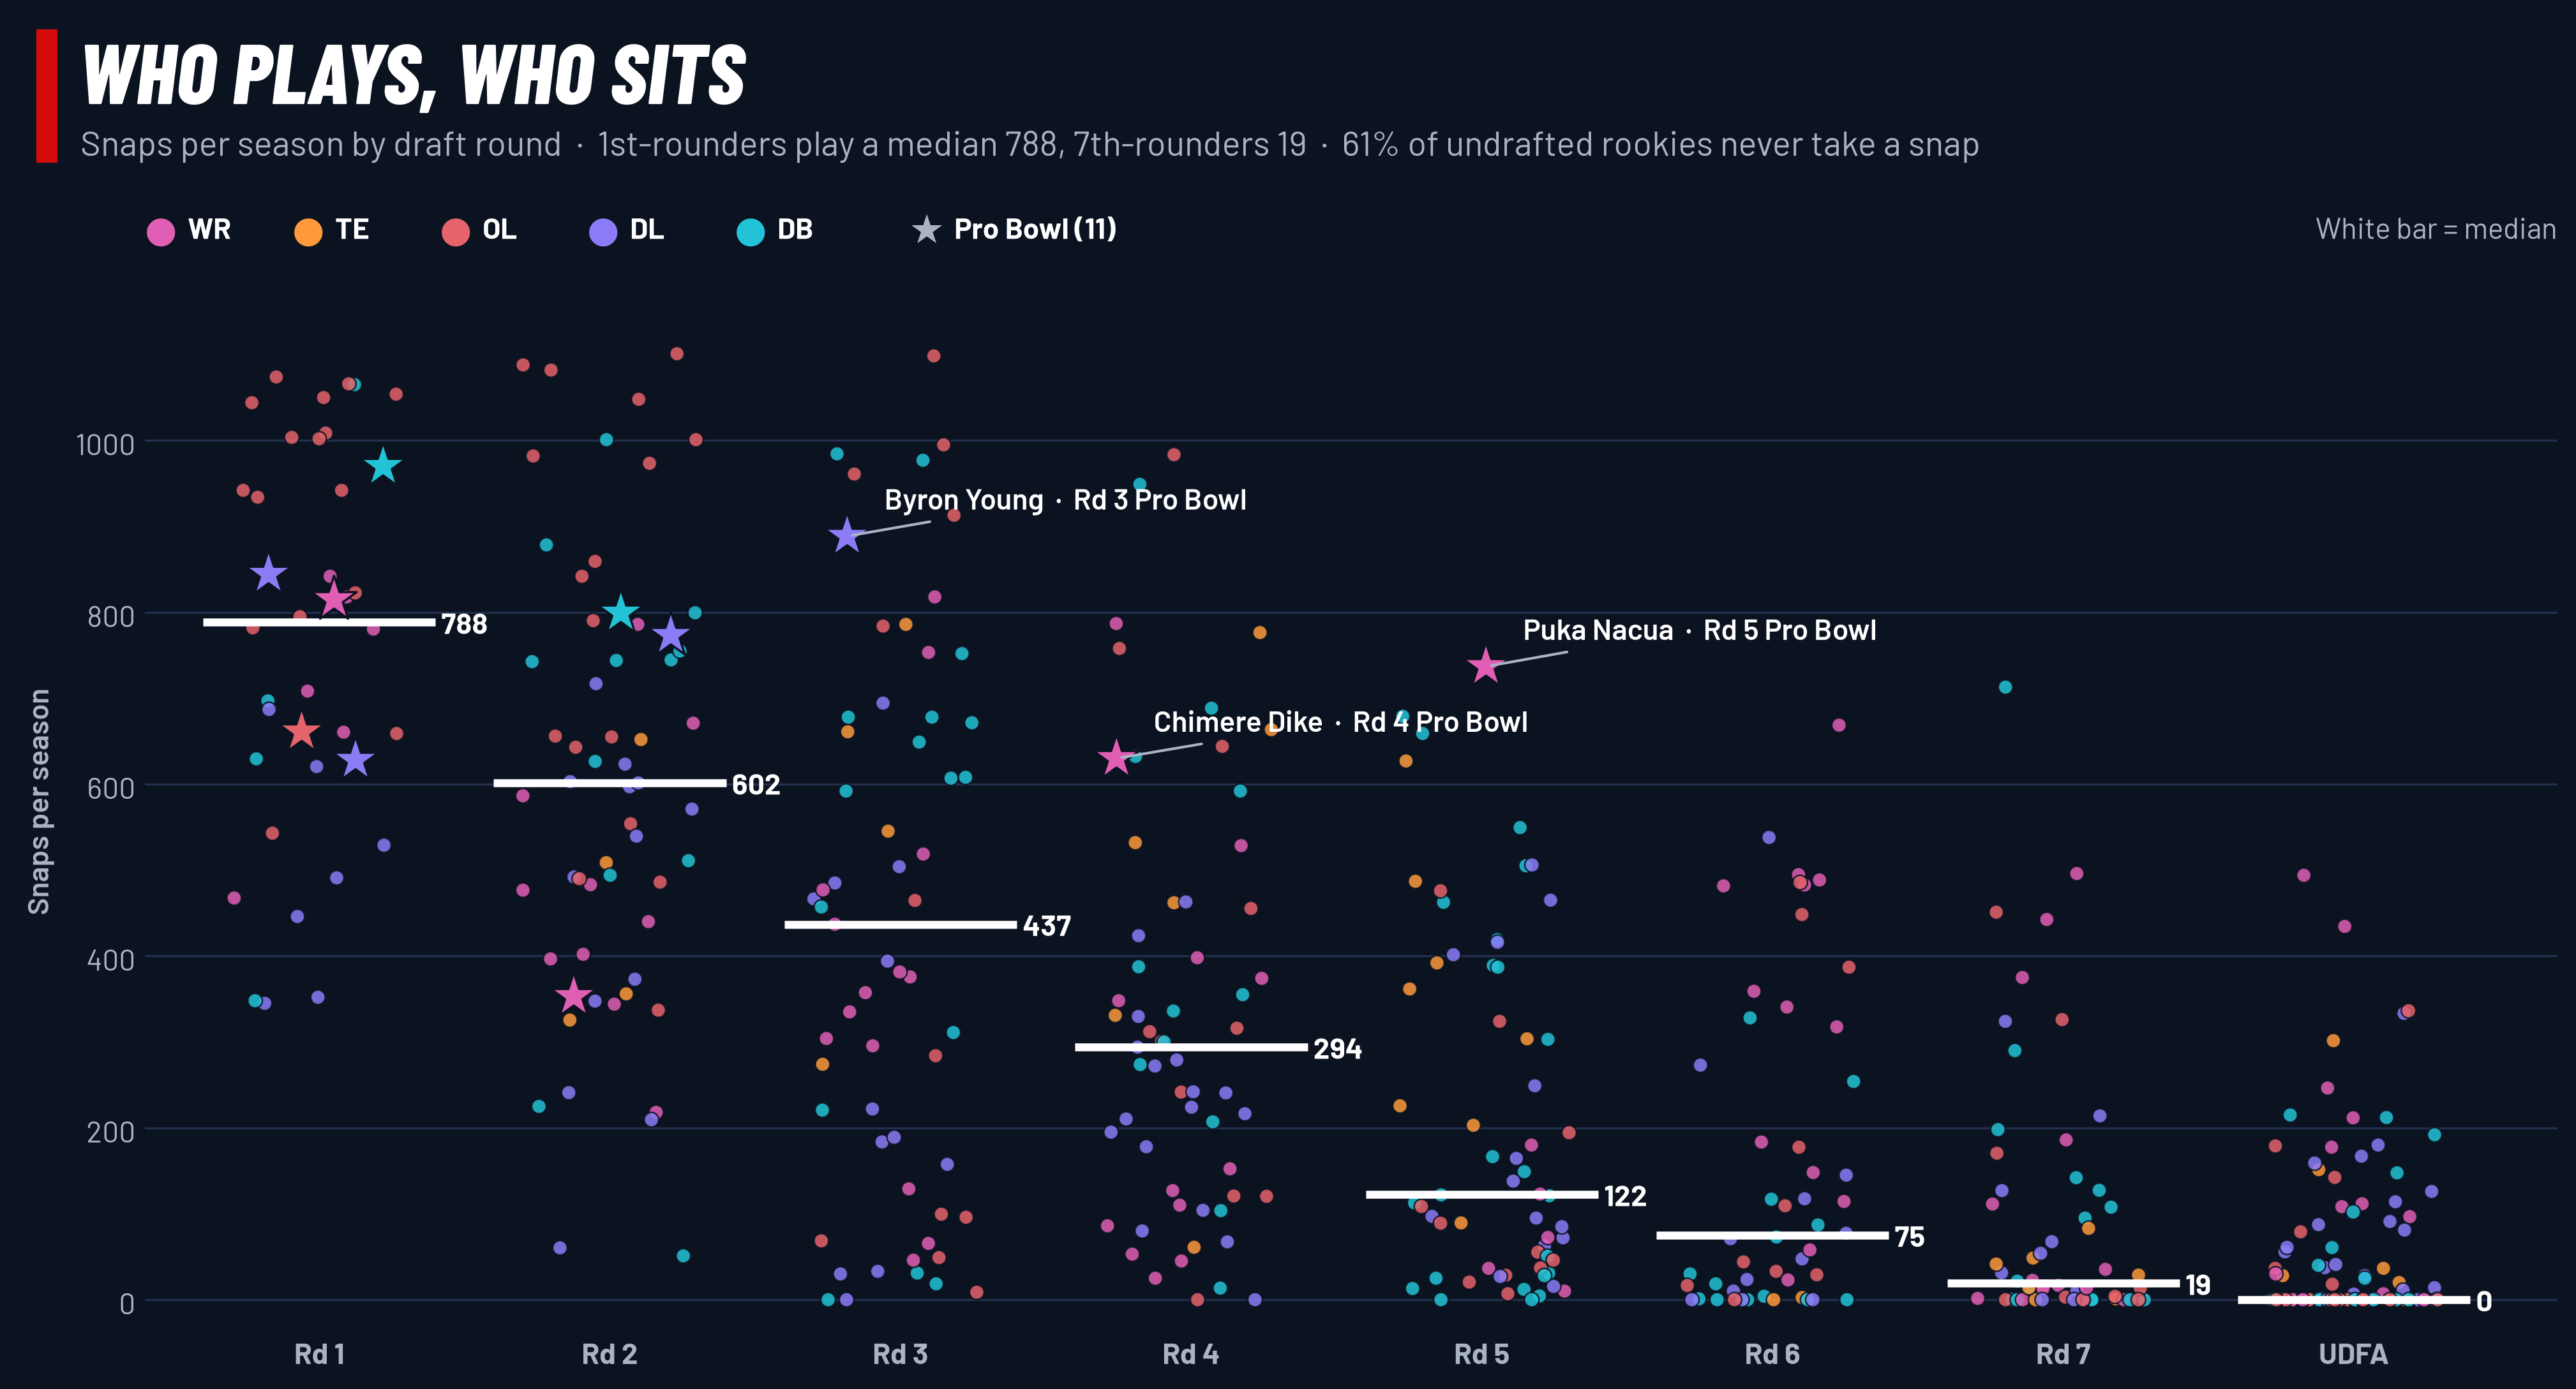

In [9]:
# Offensive + defensive snaps per season in the league (no special teams; 2023 class: 3 seasons, 2025 class: 1)
ROUNDS = [*map(str, range(1, 8)), "UDFA"]
car = (cohort.with_columns(rd=pl.col("draft_round").cast(pl.String).fill_null("UDFA"),
                           per_season=pl.sum_horizontal(pl.col("career_offensive_snaps", "career_defensive_snaps")
                                                        .fill_null(0)) / (2026 - pl.col("draft_year")),
                           pro_bowls=pl.col("pro_bowl_original_ballot").fill_null(0))
       .to_pandas())
car["x"] = car.rd.map({r: i for i, r in enumerate(ROUNDS)}) + np.random.default_rng(3).uniform(-0.3, 0.3, len(car))
med = car.groupby("rd").per_season.median().reindex(ROUNDS)
never = (car[car.rd == "UDFA"].per_season == 0).mean()

fig = plt.figure(figsize=(14, 7.6), facecolor=NAVY)
broadcast_header(fig, "WHO PLAYS, WHO SITS",
                 f"Snaps per season by draft round  ·  1st-rounders play a median {med['1']:.0f}, 7th-rounders "
                 f"{med['7']:.0f}  ·  {never:.0%} of undrafted rookies never take a snap", top=0.97, height=0.09)
ax = fig.add_axes([0.07, 0.08, 0.9, 0.72])
ax.set_facecolor(NAVY)
for side in ax.spines.values():
    side.set_visible(False)
ax.grid(axis="y", color="#22304d", lw=0.8)
ax.set_axisbelow(True)
ax.tick_params(colors=SUBTLE, length=0, labelsize=11)

ax.scatter(car.x, car.per_season, s=30, color=car.pos.map(POS_COLORS), alpha=0.85, edgecolor=NAVY, lw=0.6, zorder=3)
for i, r in enumerate(ROUNDS):
    ax.plot([i - 0.4, i + 0.4], [med[r]] * 2, color="white", lw=3, solid_capstyle="butt", zorder=4)
    ax.text(i + 0.42, med[r], f"{med[r]:.0f}", color="white", fontsize=11, fontweight="bold", va="center", zorder=4)

# Pro Bowlers become stars in their position colour; name the ones drafted after round 2
pb = car[car.pro_bowls > 0]
ax.scatter(pb.x, pb.per_season, s=320, marker="*", color=pb.pos.map(POS_COLORS), edgecolor=NAVY, lw=0.8, zorder=5)
for _, r in pb[pb.rd.astype(int) > 2].iterrows():
    ax.annotate(f"{r.display_name}  ·  Rd {r.rd} Pro Bowl", (r.x, r.per_season), xytext=(14, 10),
                textcoords="offset points", color="white", fontsize=11, fontweight="semibold",
                arrowprops=dict(arrowstyle="-", color=SUBTLE, lw=1), zorder=6)

ax.set_xticks(range(len(ROUNDS)), [f"Rd {r}" if r != "UDFA" else r for r in ROUNDS], fontweight="bold")
ax.set_xlim(-0.6, len(ROUNDS) - 0.3)
ax.set_ylim(-30, car.per_season.max() * 1.08)
ax.set_ylabel("Snaps per season", color=SUBTLE, fontweight="semibold", labelpad=8)

# Key: one dot per position group, then the Pro Bowl ring
x = 0.07
for g in POS_COLORS:
    fig.text(x, 0.835, "●", color=POS_COLORS[g], fontsize=14, va="center")
    fig.text(x + 0.016, 0.835, g, color="white", fontsize=11, fontweight="bold", va="center")
    x += 0.055
fig.text(x + 0.01, 0.835, "★", color=SUBTLE, fontsize=15, va="center")
fig.text(x + 0.027, 0.835, f"Pro Bowl ({len(pb)})", color="white", fontsize=11, fontweight="bold", va="center")
fig.text(0.97, 0.835, "White bar = median", color=SUBTLE, fontsize=11, ha="right", va="center")
plt.show()


**2. Playing well at your job.** `player_play.csv` has a different stat for each position, so "good" means something different for each group. The charts below use one stat per group, for rookies with enough regular-season plays to trust it:

- **WR + TE:** `separation_at_pass_forward`, the yards between the receiver and the nearest defender when the ball is thrown, averaged over every route they ran.
- **OL:** `pressure_allowed`, the share of pass blocks where the QB they protected got pressured.
- **DL:** `player_get_off`, seconds from the snap until he crosses the line of scrimmage, against how often he pressures the QB when he rushes (`blitzing == TRUE`).
- **DB:** there is no coverage grade, so two stand-ins. **Burst after the throw** comes from game tracking: the speed a DB gains in the second after the `pass_forward` event, i.e. how hard he drives once the ball is out. **Tackles per run play** counts a tackle as 1 and an assist as ½.

> **The DB panel is a stand-in, not a coverage grade.** `coverage_assignment` says who a DB was covering, not how it went, and the game tracking has no ball, so burst can't tell whether he's driving *toward* the ball. Both stats also depend on role: safeties play deep facing the QB, so they make more tackles and have more room to accelerate than cornerbacks. Compare cornerbacks with cornerbacks and safeties with safeties.


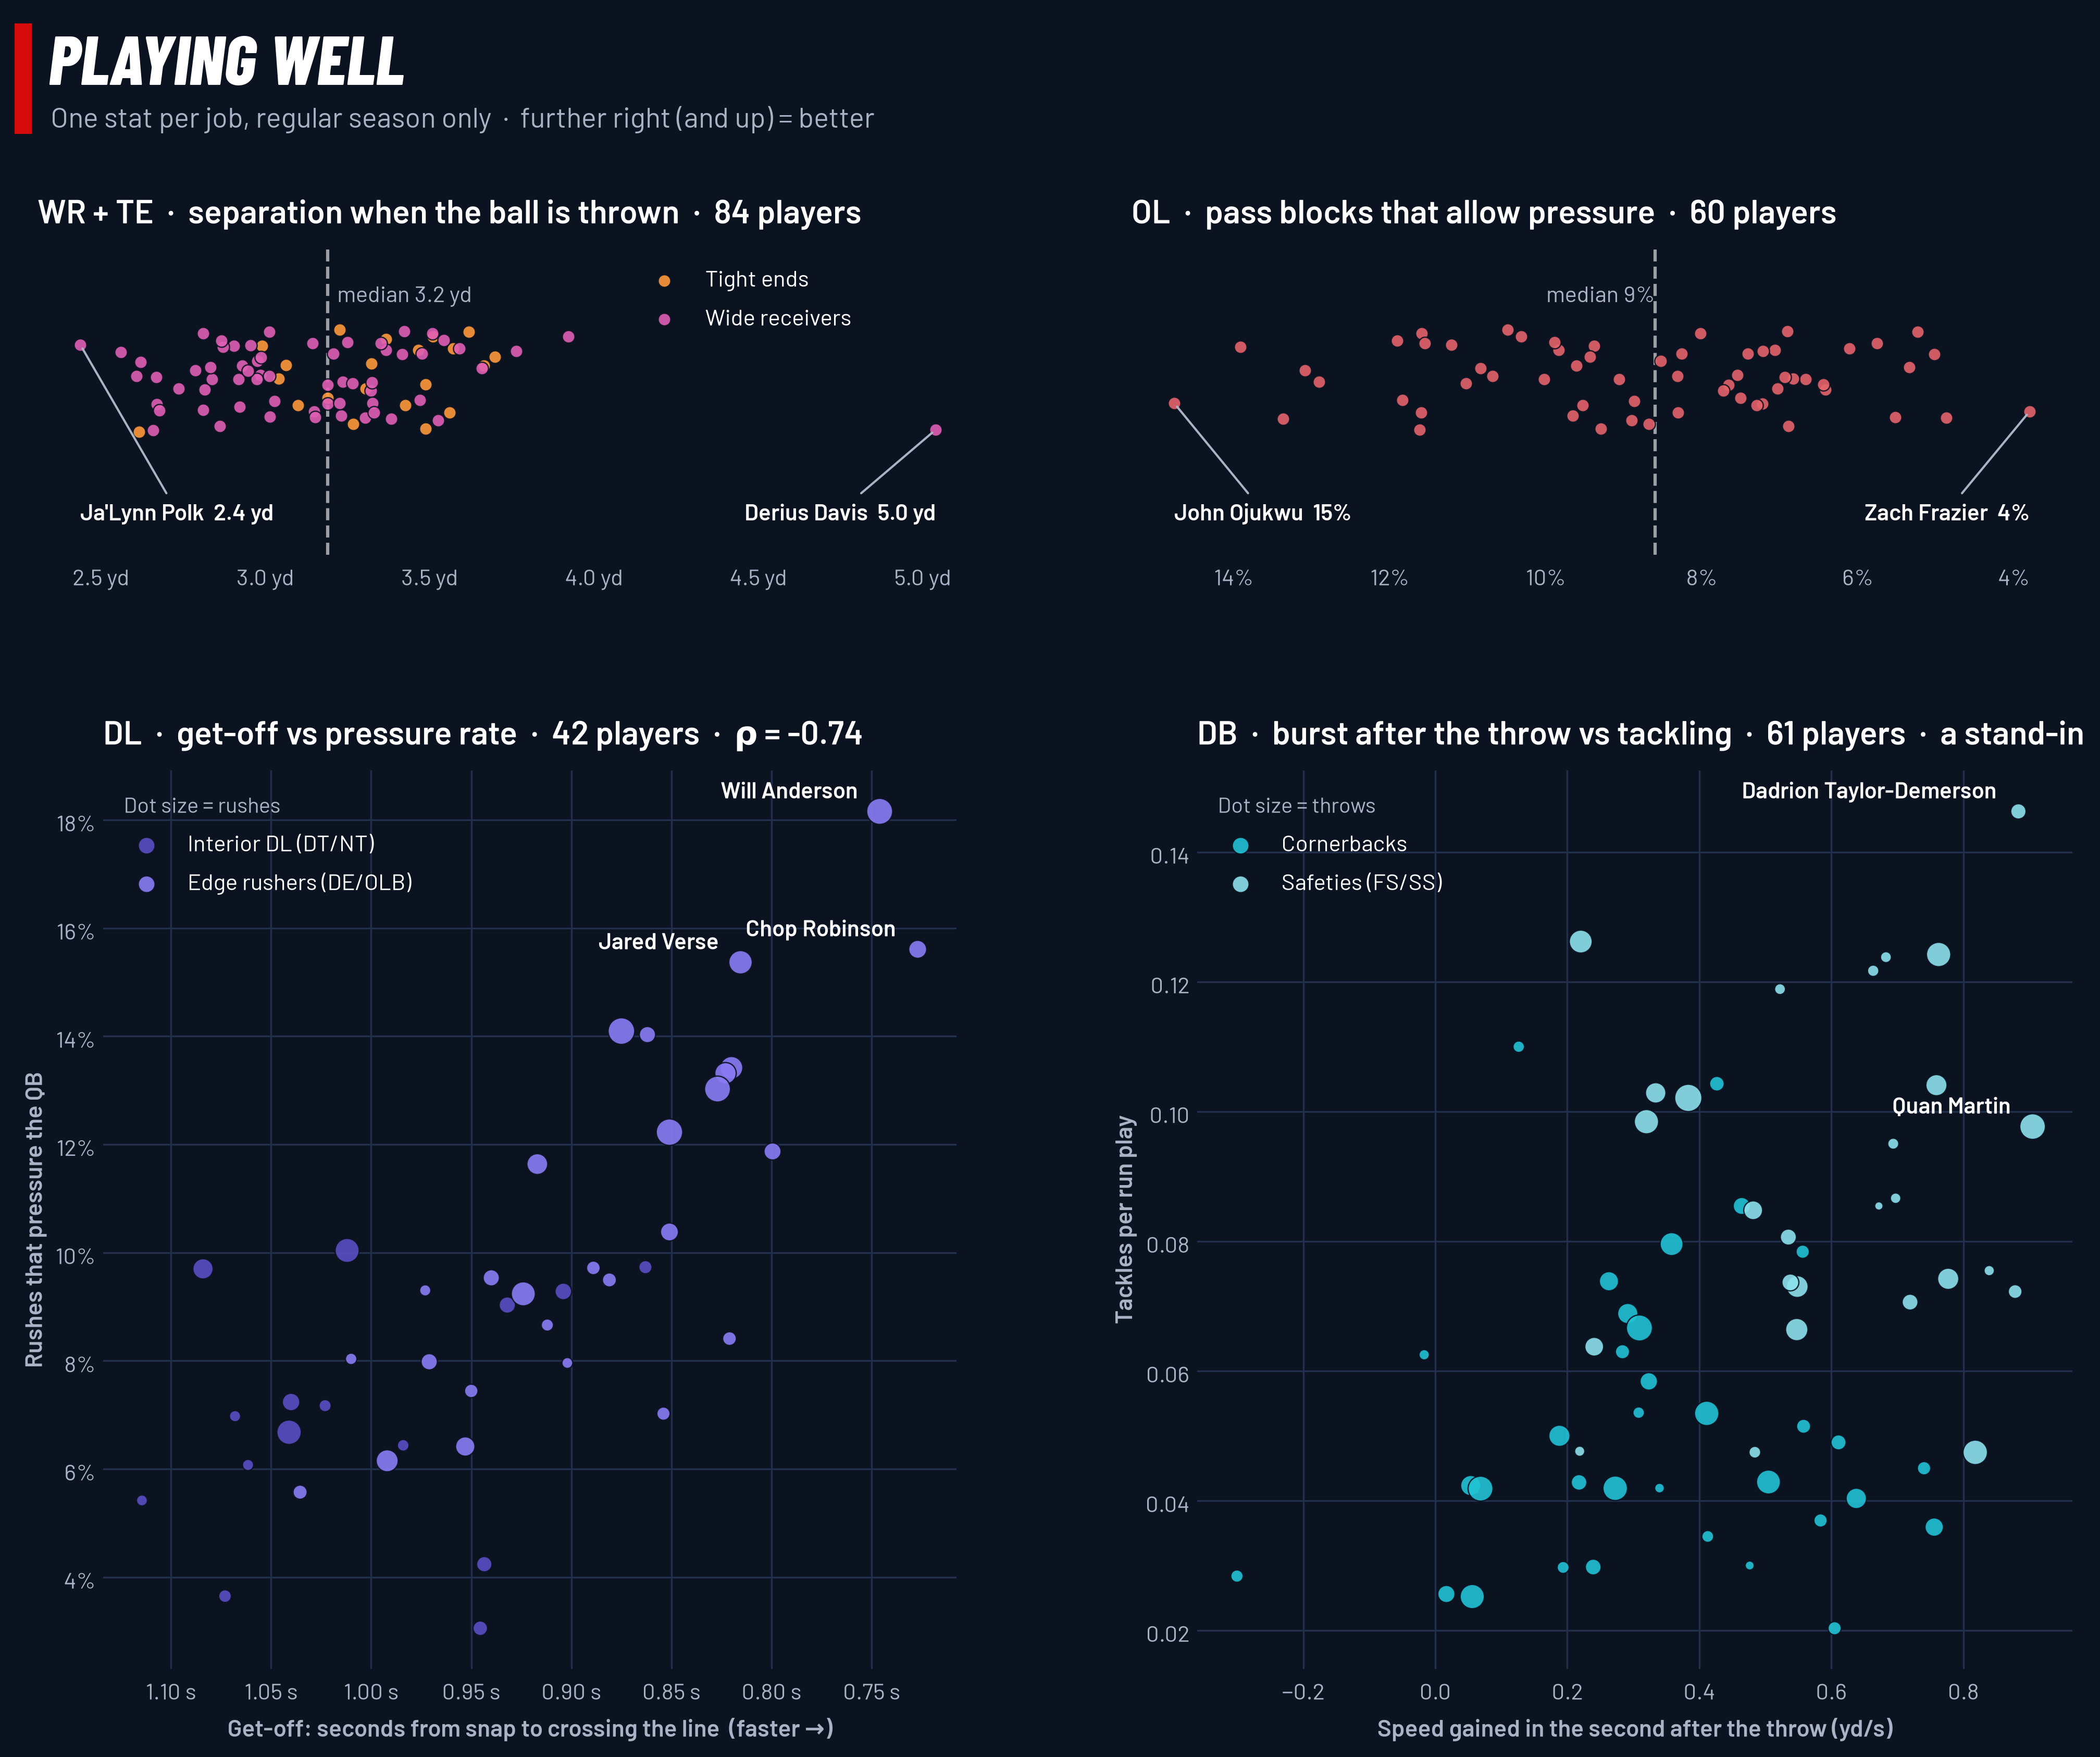

In [10]:
reg_games = read("games").filter(pl.col("season_type") == "REG").select("game_id")
plays = (read("player_play").join(reg_games, on="game_id").filter(pl.col("play_nullified_by_penalty") == "N")
         .join(cohort.select("nfl_id", "display_name", "pos", "nfl_position"), on="nfl_id"))

# One row per player: how many plays the stat covers, and the stat
rec = (plays.filter(pl.col("pos").is_in(["WR", "TE"]) & pl.col("separation_at_pass_forward").is_not_null())
       .group_by("nfl_id", "display_name", "pos").agg(n=pl.len(), value=pl.col("separation_at_pass_forward").mean())
       .filter(pl.col("n") >= 100).to_pandas())
ol = (plays.filter((pl.col("pos") == "OL") & pl.col("pressure_allowed").is_not_null())
      .group_by("nfl_id", "display_name", "pos").agg(n=pl.len(), value=pl.col("pressure_allowed").mean())
      .filter(pl.col("n") >= 200).to_pandas())
dl = (plays.filter((pl.col("pos") == "DL") & pl.col("blitzing"))
      .group_by("nfl_id", "display_name", "nfl_position")
      .agg(n=pl.len(), get_off=pl.col("player_get_off").median(), pressure=pl.col("time_to_pressure").is_not_null().mean())
      .filter((pl.col("n") >= 200) & pl.col("get_off").is_not_null()).to_pandas())
dl["group"] = np.where(dl.nfl_position.isin(["DE", "OLB"]), "EDGE", "IDL")
rho = dl[["get_off", "pressure"]].corr(method="spearman").iloc[0, 1]

fig = plt.figure(figsize=(14, 11.5), facecolor=NAVY)
broadcast_header(fig, "PLAYING WELL",
                 "One stat per job, regular season only  ·  further right (and up) = better",
                 top=0.975, height=0.06)


def strip(rect, df, title, fmt, better_low=False):
    """Every qualifying player as a dot along the stat; the best and worst named, the median marked."""
    ax = panel(rect, title)
    y = np.random.default_rng(1).uniform(-0.3, 0.3, len(df))
    for g, d in df.groupby("pos"):
        ax.scatter(d.value, y[d.index], s=34, color=POS_COLORS[g], alpha=0.9, edgecolor=NAVY, lw=0.6, zorder=3,
                   label=POS_NAMES[g])
    if df.pos.nunique() > 1:
        ax.legend(loc="upper left", bbox_to_anchor=(0.62, 1.02), frameon=False, labelcolor="white", fontsize=10.5)
    mid = df.value.median()
    ax.axvline(mid, color="white", lw=1.5, ls="--", alpha=0.6, zorder=2)
    ax.text(mid, 0.5, f"  median {fmt(mid)}", color=SUBTLE, fontsize=10.5, ha="right" if better_low else "left",
            va="center")
    # Name the best (drawn on the right) and the worst (on the left), below the dots
    best, worst = (df.value.idxmin(), df.value.idxmax()) if better_low else (df.value.idxmax(), df.value.idxmin())
    for i, ha in ((best, "right"), (worst, "left")):
        ax.annotate(f"{df.display_name[i]}  {fmt(df.value[i])}", (df.value[i], y[i]), xytext=(df.value[i], -0.75),
                    ha=ha, va="center", color="white", fontsize=10.5, fontweight="semibold",
                    arrowprops=dict(arrowstyle="-", color=SUBTLE, lw=1, shrinkA=0))
    if better_low:
        ax.invert_xaxis()
    ax.set_ylim(-1, 0.75)
    ax.set_yticks([])
    ax.xaxis.set_major_formatter(lambda v, _: fmt(v))
    return ax


strip([0.04, 0.68, 0.43, 0.17], rec, f"WR + TE  ·  separation when the ball is thrown  ·  {len(rec)} players",
      lambda v: f"{v:.1f} yd")
strip([0.54, 0.68, 0.43, 0.17], ol, f"OL  ·  pass blocks that allow pressure  ·  {len(ol)} players",
      lambda v: f"{v:.0%}", better_low=True)

# DL: faster get-off (to the right) goes with more pressure (up)
a3 = panel([0.07, 0.06, 0.39, 0.5], f"DL  ·  get-off vs pressure rate  ·  {len(dl)} players  ·  ρ = {rho:.2f}")
a3.grid(color="#22304d", lw=0.8)
a3.set_axisbelow(True)
for g in ("IDL", "EDGE"):
    d = dl[dl.group == g]
    a3.scatter(d.get_off, d.pressure, s=d.n / 8, color=GROUP_COLORS[g], alpha=0.9, edgecolor=NAVY, lw=0.6, zorder=3,
               label=GROUP_NAMES[g])
for _, r in dl.nlargest(3, "pressure").iterrows():
    a3.annotate(r.display_name, (r.get_off, r.pressure), xytext=(-10, 6), textcoords="offset points", ha="right",
                color="white", fontsize=10.5, fontweight="semibold")
a3.invert_xaxis()
a3.xaxis.set_major_formatter(lambda v, _: f"{v:.2f} s")
a3.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
a3.set_xlabel("Get-off: seconds from snap to crossing the line  (faster →)", color=SUBTLE, fontweight="semibold")
a3.set_ylabel("Rushes that pressure the QB", color=SUBTLE, fontweight="semibold")
key = a3.legend(loc="upper left", frameon=False, labelcolor="white", fontsize=10.5, title="Dot size = rushes",
                title_fontsize=10, alignment="left")
key.get_title().set_color(SUBTLE)
for h in key.legend_handles:
    h.set_sizes([60])

# DB stand-ins. Burst: speed gained over the 10 tracking frames (1 s) after the throw, on regular-season dropbacks
throws = plays.filter((pl.col("pos") == "DB") & (pl.col("pass_result").fill_null("") != "")).select("game_id", "play_id", "nfl_id")
burst = (pl.concat([pl.scan_csv(DATA / f"game_tracking_{y}.csv", null_values="NA") for y in (2023, 2024, 2025)])
         .join(throws.lazy(), on=["game_id", "play_id", "nfl_id"])
         .sort("game_id", "play_id", "nfl_id", "time")
         .with_columns(i=pl.int_range(pl.len()).over("game_id", "play_id", "nfl_id"))
         .with_columns(thrown=pl.col("i").filter(pl.col("event") == "pass_forward").first().over("game_id", "play_id", "nfl_id"))
         .filter(pl.col("i").is_between(pl.col("thrown"), pl.col("thrown") + 10))
         .group_by("game_id", "play_id", "nfl_id").agg(gain=pl.col("s").last() - pl.col("s").first(), frames=pl.len())
         .filter(pl.col("frames") == 11)
         .group_by("nfl_id").agg(n=pl.len(), burst=pl.col("gain").mean())
         .collect())
tackling = (plays.filter((pl.col("pos") == "DB") & (pl.col("pass_result").fill_null("") == ""))
            .group_by("nfl_id", "display_name", "nfl_position")
            .agg(runs=pl.len(), tackles=(pl.col("tackle").fill_null(0) + 0.5 * pl.col("assist").fill_null(0)).mean()))
db = burst.join(tackling, on="nfl_id").filter((pl.col("n") >= 100) & (pl.col("runs") >= 100)).to_pandas()
db["group"] = np.where(db.nfl_position == "CB", "CB", "S")
DB_COLORS = {"CB": POS_COLORS["DB"], "S": "#8ee3ee"}
DB_NAMES = {"CB": "Cornerbacks", "S": "Safeties (FS/SS)"}

a4 = panel([0.57, 0.06, 0.4, 0.5], f"DB  ·  burst after the throw vs tackling  ·  {len(db)} players  ·  a stand-in")
a4.grid(color="#22304d", lw=0.8)
a4.set_axisbelow(True)
for g in ("CB", "S"):
    d = db[db.group == g]
    a4.scatter(d.burst, d.tackles, s=d.n / 8, color=DB_COLORS[g], alpha=0.9, edgecolor=NAVY, lw=0.6, zorder=3,
               label=DB_NAMES[g])
for _, r in pd.concat([db.nlargest(2, "burst"), db.nlargest(1, "tackles")]).drop_duplicates("nfl_id").iterrows():
    a4.annotate(r.display_name, (r.burst, r.tackles), xytext=(-10, 6), textcoords="offset points", ha="right",
                color="white", fontsize=10.5, fontweight="semibold")
a4.yaxis.set_major_formatter(lambda v, _: f"{v:.2f}")
a4.set_xlabel("Speed gained in the second after the throw (yd/s)", color=SUBTLE, fontweight="semibold")
a4.set_ylabel("Tackles per run play", color=SUBTLE, fontweight="semibold")
key = a4.legend(loc="upper left", frameon=False, labelcolor="white", fontsize=10.5, title="Dot size = throws",
                title_fontsize=10, alignment="left")
key.get_title().set_color(SUBTLE)
for h in key.legend_handles:
    h.set_sizes([60])
plt.show()


---
## 6 · First link: Combine meets Sundays
Both datasets track the same players at 10 Hz on the same yard grid, so the simplest first link is speed: does how fast a player runs at the Combine show up in games?

Take each rookie's **top speed in the 40** (from the Combine tracking) and his **top speed in regular-season games**: the 95th percentile of his per-play top speeds, so one sensor blip can't win.


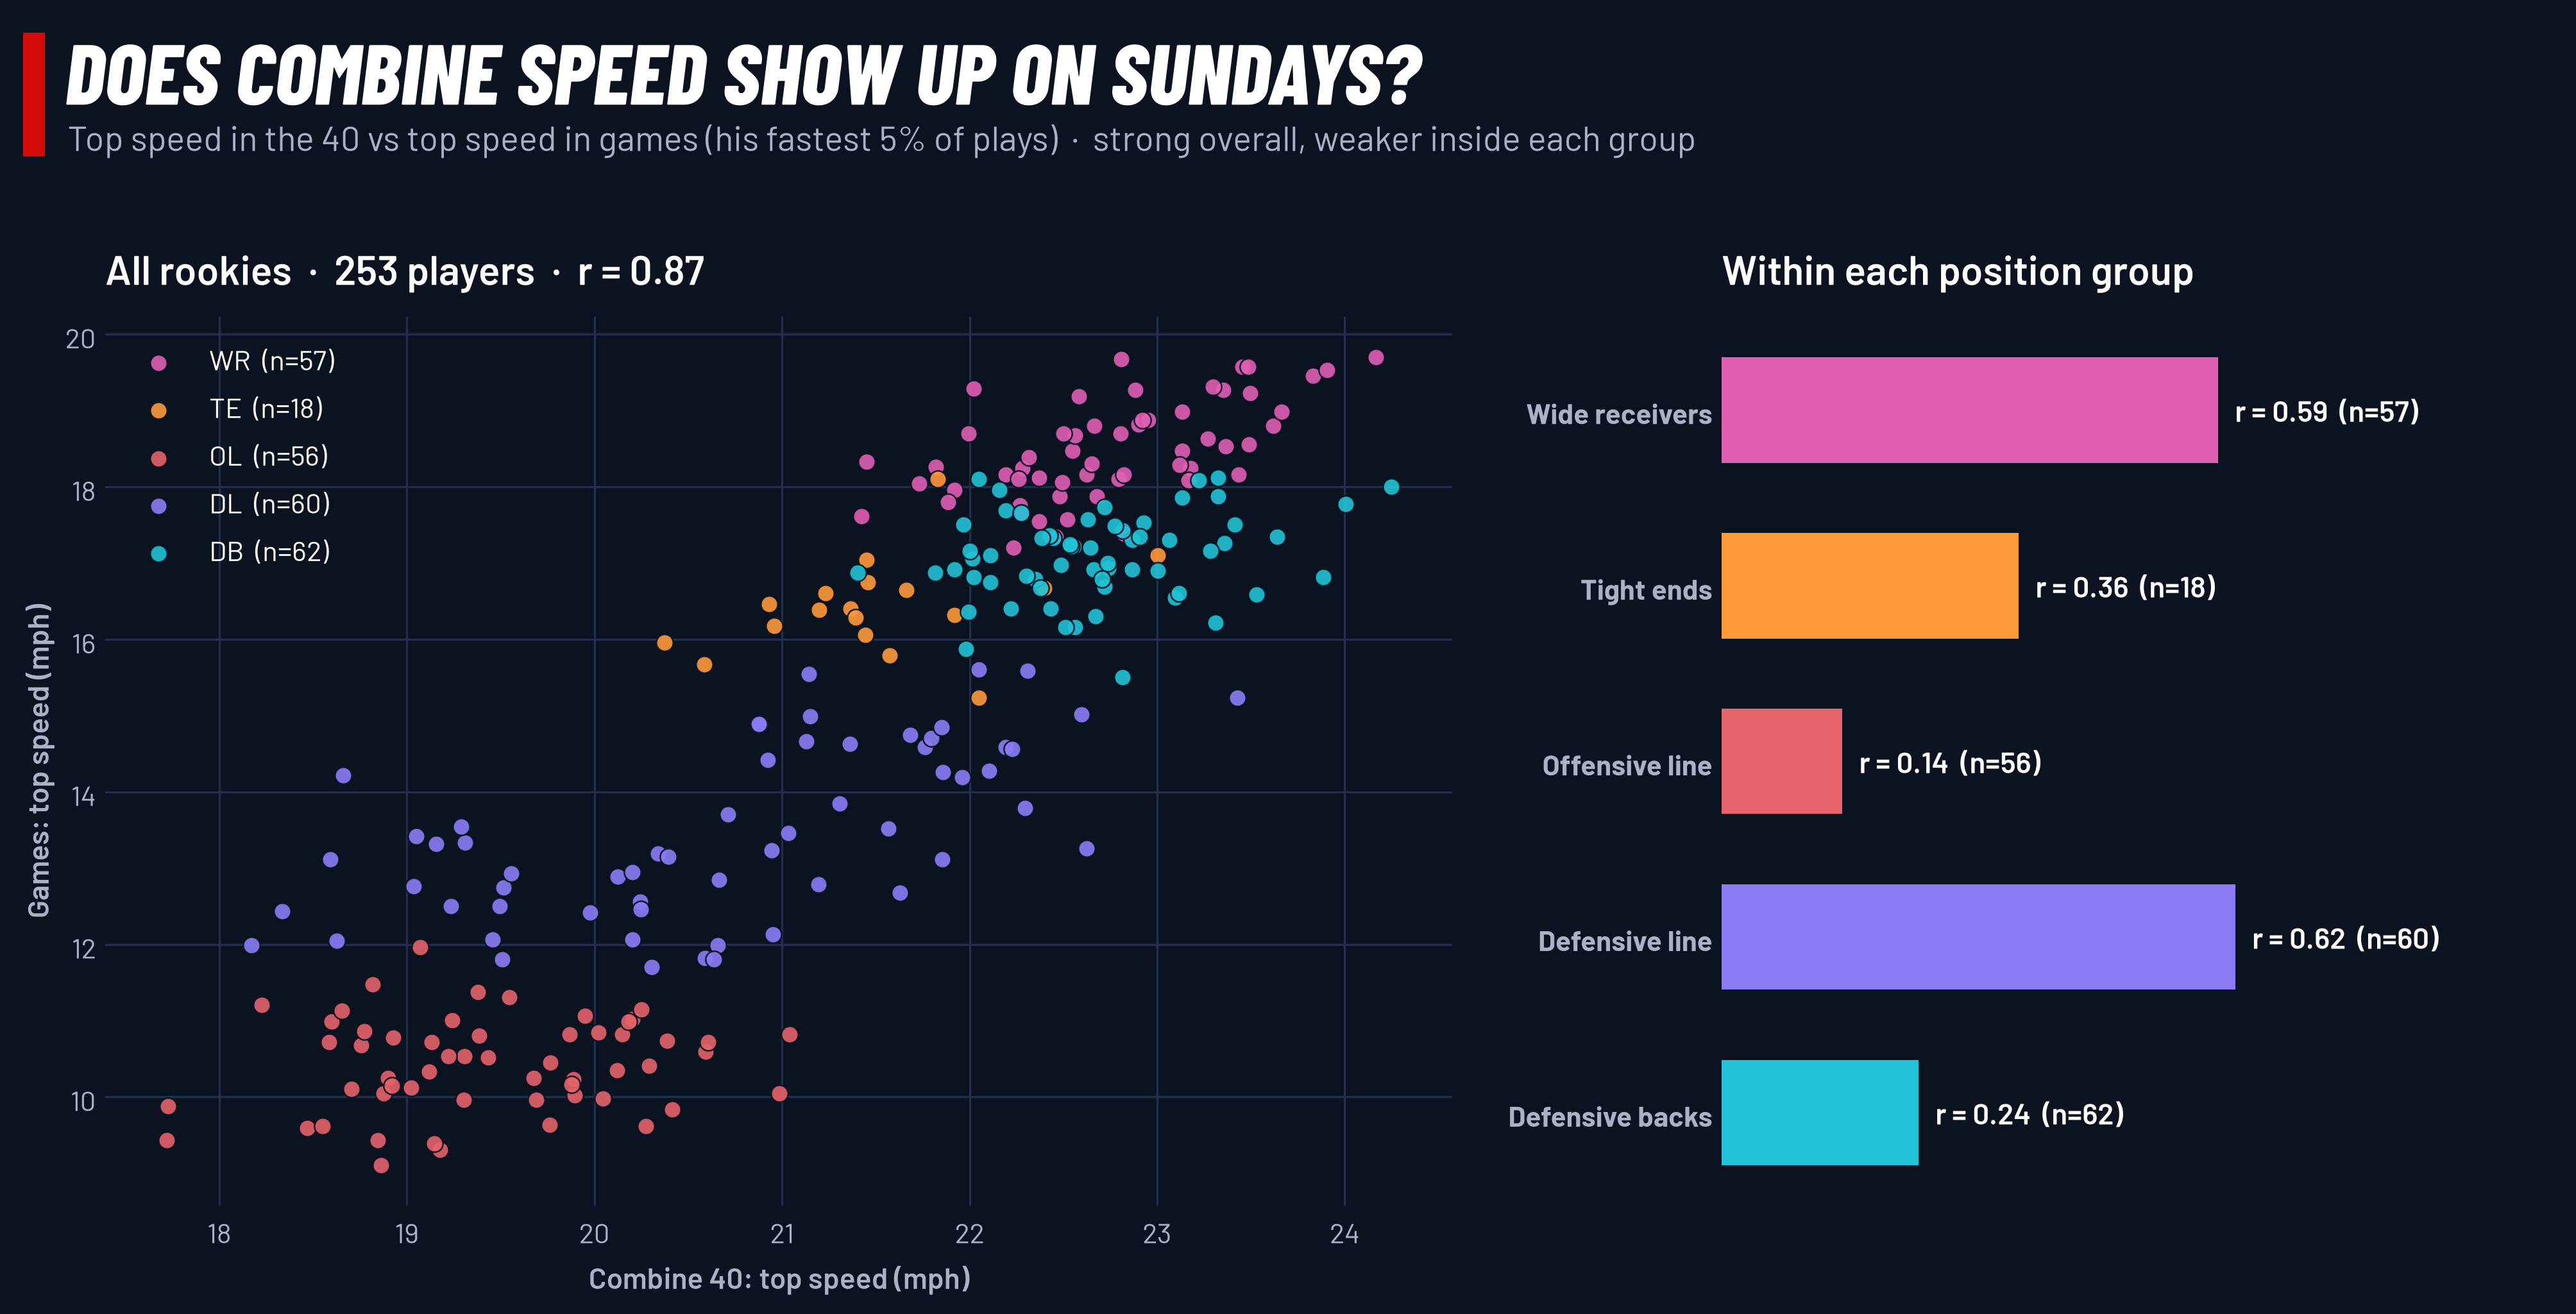

In [11]:
# Top speed in the 40 (tracking) vs top speed in regular-season games, in mph
YDS_TO_MPH = 3600 / 1760
combine_top = forty.groupby("nfl_id").s.max().mul(YDS_TO_MPH).rename("combine_top").reset_index()
game_top = (pl.concat([pl.scan_csv(DATA / f"game_tracking_{y}.csv", null_values="NA").select("game_id", "play_id", "nfl_id", "s")
                       for y in (2023, 2024, 2025)])
            .join(reg_games.lazy(), on="game_id")
            .group_by("nfl_id", "game_id", "play_id").agg(play_max=pl.col("s").max())          # fastest moment of each play
            .group_by("nfl_id").agg(game_top=pl.col("play_max").quantile(0.95) * YDS_TO_MPH,    # his fastest 5% of plays
                                    plays=pl.len())
            .filter(pl.col("plays") >= 100).collect().to_pandas())
link = game_top.merge(combine_top, on="nfl_id").merge(cohort.select("nfl_id", "pos").to_pandas(), on="nfl_id")
r_all = np.corrcoef(link.combine_top, link.game_top)[0, 1]

fig = plt.figure(figsize=(14, 7), facecolor=NAVY)
broadcast_header(fig, "DOES COMBINE SPEED SHOW UP ON SUNDAYS?",
                 "Top speed in the 40 vs top speed in games (his fastest 5% of plays)  ·  strong overall, weaker inside each group",
                 top=0.97, height=0.09)

a1 = panel([0.06, 0.1, 0.5, 0.66], f"All rookies  ·  {len(link)} players  ·  r = {r_all:.2f}")
a1.grid(color="#22304d", lw=0.8)
a1.set_axisbelow(True)
for g in POS_ORDER:
    d = link[link.pos == g]
    a1.scatter(d.combine_top, d.game_top, s=40, color=POS_COLORS[g], alpha=0.9, edgecolor=NAVY, lw=0.6, zorder=3,
               label=f"{g}  (n={len(d)})")
a1.set_xlabel("Combine 40: top speed (mph)", color=SUBTLE, fontweight="semibold")
a1.set_ylabel("Games: top speed (mph)", color=SUBTLE, fontweight="semibold")
a1.legend(loc="upper left", frameon=False, labelcolor="white", fontsize=10.5)

# Correlation inside each position group (skipping groups too small to say anything)
rs = [(g, np.corrcoef(link[link.pos == g].combine_top, link[link.pos == g].game_top)[0, 1], (link.pos == g).sum())
      for g in POS_ORDER if (link.pos == g).sum() >= 8]
a2 = panel([0.66, 0.1, 0.31, 0.66], "Within each position group")
for i, (g, r, n) in enumerate(rs):
    y = len(rs) - 1 - i
    a2.barh(y, r, color=POS_COLORS[g], height=0.6)
    a2.text(max(r, 0) + 0.02, y, f"r = {r:.2f}  (n={n})", va="center", color="white", fontsize=11, fontweight="semibold")
a2.set_yticks(range(len(rs)), [POS_NAMES[g] for g, *_ in rs][::-1], fontweight="bold")
a2.set_xlim(0, 1)
a2.set_xticks([])
plt.show()


**What this tells you:** nobody runs as fast in a game as in a straight 40 (football is turns, traffic and stops). Across all rookies, Combine speed and game speed line up well, but much of that is just *position*: linemen are slower than receivers. **Inside** a position group the link is weaker. That's the real game in this competition: find signal *within* a group, about something that **wins plays**, not just "fast guys are fast".

## Where to go next

The hosts suggest going **narrow**: one movement, one position group, one drill. A few starting ideas:

| Idea | Combine side | Sunday side |
|---|---|---|
| **Cuts → open receivers** | how fast a WR slows down and re-accelerates in route drills | `separation_at_pass_forward` |
| **First step → pressure** | DL acceleration off the line in the pass-rush drill | `player_get_off`, `time_to_pressure` |
| **Mirror → protection** | OL lateral quickness in the mirror drill | `pressure_allowed` |
| **Hips → coverage** | DB transition time in backpedal-and-break drills | in-game tracking on coverage snaps |

### Mini glossary
**Snap**: the moment the play starts · **Down**: one attempt · **LOS**: line of scrimmage · **Route**: the path a receiver runs ·
**Separation**: distance from receiver to nearest defender · **Pressure**: a defender forces the QB to hurry · **Sack**: QB tackled behind the LOS ·
**UDFA**: undrafted free agent · **10 Hz**: 10 samples per second

*If this helped you get started, an upvote helps others find it. Good luck in the Big Data Bowl! 🏈*